# 2026.10.28(수) 19h30~ 6강 · Keras로 음성 인식 모델 구성하기

5강의 X·y를 이어 받아 입력 전처리, 정답 구성, Encoder–Decoder, 학습과 자유 생성까지 연결합니다.

**학습 목표:** 각 배열의 의미를 설명하고 Keras 모델을 직접 구성하여 가중치 업데이트와 추론을 확인한다.

| 구성 | 핵심 질문 | 완료 결과 |
|---|---|---|
| 1교시 | 저장 음성을 같은 규칙으로 모델에 넣을 수 있는가? | Log-Mel 대조·정규화·음성 마스크 |
| 2교시 | 다음 토큰을 예측하도록 정답을 어떻게 구성하는가? | BOS/EOS·Decoder 입력·정답·PAD 처리 |
| 3교시 | Keras의 층 사이에서 배열이 어떻게 흐르는가? | Encoder–Decoder·순전파·마스크 동작 확인 |
| 4교시 | 학습과 실제 생성은 무엇이 다른가? | fit·가중치 변화·한 단계 추론·새 음성 실험·결과 보고 |

**범위:** 5강 배치의 음성 3개를 모두 학습에 사용하는 소규모 구조 실습이다. 모델은 실제로 학습하지만 새로운 음성의 인식 성능을 보장하지 않는다. 4-S에서 학습에 쓰지 않은 음성 2개로 이 한계를 직접 확인하고, 7강에서는 사전학습된 Whisper를 사용한다.

**실행 시간:** CPU 기준 전체 2분 안팎이며, 대부분은 4-2 학습(약 1분)이다.


<a id="practice-0"></a>
## 실습 0 · 준비 · 환경과 데이터 경로 [기본 실습]

**이론 연결:** [HTML 0 · 준비 · 환경과 데이터 경로](lesson06_theory.html#practice-0)

**실행 목적:** GPU 목록이 비어 있어도 진행할 수 있습니다. 필수 파일 세 개는 모두 있어야 합니다.

```text
실습폴더/
├─ lesson06_practice.ipynb
├─ lesson06_theory.html
├─ data/
│  ├─ speech_manifest.json      # 음성 목록 (id, file, reference, sha256)
│  └─ speech/                   # WAV 5개
└─ results/
   ├─ lesson05_batch.npz        # 5강 4-7에서 SAVE=True로 저장
   └─ lesson05_record.json
```

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [2]:
# 라이브러리 불러오기
from pathlib import Path
from math import gcd
import json, hashlib, copy, platform
import numpy as np
from scipy.io import wavfile
from scipy.signal import stft, resample_poly
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(0)  # 실행마다 같은 결과가 나오도록 고정

# 실습 폴더 위치
BASE = Path.cwd()  # 필요하면 5강 실습 폴더의 절대 경로로 변경
DATA = BASE / "data"
RESULTS = BASE / "results"
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("실습 폴더:", BASE)
# 세 파일이 모두 True여야 다음으로 진행합니다.
for p in [DATA/'speech_manifest.json', RESULTS/'lesson05_batch.npz', RESULTS/'lesson05_record.json']:
    print(p.name, p.is_file())
print("GPU:", tf.config.list_physical_devices('GPU'))  # []이어도 진행 가능

Python: 3.11.13 TensorFlow: 2.16.2
speech_manifest.json True
lesson05_batch.npz True
lesson05_record.json True
GPU: []


### 관찰·직접 적용 · 0

세 경로의 True 여부와 실행 중인 TensorFlow 버전을 기록하세요. False인 경로가 있으면 1-1 이전에 수정하세요.

**완료 기준:** GPU 목록이 비어 있어도 진행할 수 있습니다. 필수 파일 세 개는 모두 있어야 합니다.

### 내 기록 · 0

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 0 — 먼저 자신의 기록을 작성하세요</summary>

노트북이 놓인 위치와 커널의 현재 작업 폴더가 다를 수 있습니다. BASE는 실제 data·results가 있는 폴더를 가리켜야 합니다.

</details>

<a id="practice-1-1"></a>
## 실습 1-1 · 5강 저장 결과와 원본 연결 [기본 실습]

**이론 연결:** [HTML 1-1 · 5강 저장 결과와 원본 연결](lesson06_theory.html#practice-1-1)

**실행 목적:** 5강 기본 선택을 유지했다면 B=3, Mel 특징 수=40입니다. 길이는 저장 결과에 따라 읽습니다. 목록에 있는 나머지 음성 파일도 함께 확인합니다(4-S에서 사용).

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [21]:
# 5강 기록과 음성 목록 읽기
record = json.loads((RESULTS/'lesson05_record.json').read_text(encoding='utf-8'))
manifest = json.loads((DATA/'speech_manifest.json').read_text(encoding='utf-8'))
if not isinstance(manifest, list) or not manifest:
    raise ValueError("5강 Manifest는 항목 리스트여야 합니다.")

# ID → 항목 사전 만들기 (빈 값·중복 ID 검사)
by_id = {}
for row in manifest:
    for key in ('id', 'file', 'reference'):
        if not isinstance(row.get(key), str) or not row[key].strip():
            raise ValueError(f"비어 있거나 잘못된 항목: {key}") # raise = error 띄우고 멈춰라
    if row['id'] in by_id:
        raise ValueError("중복 ID")
    by_id[row['id']] = row

# 5강에서 저장한 배열
with np.load(RESULTS/'lesson05_batch.npz', allow_pickle=False) as saved:
    X_raw = saved['batch'].astype('float32')      # (B, T, 40) 음성 특징
    X_mask = saved['mask'].astype(bool)           # (B, T) 실제 프레임 True
    X_lengths = saved['lengths'].astype('int32')  # 음성별 실제 프레임 수
    y5 = saved['label_ids'].astype('int32')       # 정답 어절 ID
    y5_mask = saved['label_mask'].astype(bool)    # 실제 어절 위치 True
    ids = saved['batch_ids'].tolist()             # 각 행의 음성 ID

# 저장 결과끼리 순서·내용이 맞는지 확인
assert ids == record['batch_ids'], "NPZ·JSON의 ID 순서가 다릅니다."
assert len(ids) == len(set(ids)) and len(ids) > 0
rows = [by_id[i] for i in ids]
references = [r['reference'] for r in rows]
assert references == record['references'], "원본 정답과 저장 정답이 다릅니다."
vocab5 = {word: int(idx) for word, idx in record['vocab'].items()}

# 목록의 모든 WAV 확인 (4-S에서 학습에 쓰지 않은 음성도 사용)
for row in manifest:
    relative = Path(row['file'])
    p = (DATA/relative).resolve()
    if relative.is_absolute() or not p.is_relative_to(DATA.resolve()):
        raise ValueError("data 안의 상대 경로를 사용하세요.")
    if not p.is_file():
        raise FileNotFoundError(p)
    if 'sha256' in row:  # 파일 내용이 바뀌지 않았는지(변조 여부) 확인
        assert hashlib.sha256(p.read_bytes()).hexdigest() == row['sha256'], "원본 변경"
print("사용 ID:", ids)
print("X:", X_raw.shape, "y5:", y5.shape, "프레임 수:", X_lengths) # 길이가 다른 3개의 문장
print("학습에 쓰지 않은 음성 수:", len(manifest) - len(ids))

print("y5 = ", y5)
print("y5_mask = ", y5_mask)

사용 ID: ['1272-128104-0001', '1272-128104-0006', '1272-128104-0008']
X: (3, 1290, 40) y5: (3, 17) 프레임 수: [ 609  792 1290]
학습에 쓰지 않은 음성 수: 2
y5 =  [[ 2  3  4  5  6  7  0  0  0  0  0  0  0  0  0  0  0]
 [ 8  9 10 11 12 13 14 15 16 17  0  0  0  0  0  0  0]
 [18 19  4 20 21 22 23 24 25 26 27 28 29 30 31 32 17]]
y5_mask =  [[ True  True  True  True  True  True False False False False False False
  False False False False False]
 [ True  True  True  True  True  True  True  True  True  True False False
  False False False False False]
 [ True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True]]


### Q. `record['vocab']`은 무엇인가? (위 셀의 `vocab5 = {word: int(idx) for word, idx in record['vocab'].items()}`)

값과 출력은 `results/lesson05_record.json`을 직접 읽어 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. `record`는 무엇인가
- 이 셀 맨 위 `record = json.loads((RESULTS/'lesson05_record.json').read_text(...))`로 만든 **파이썬 사전(dict)** 입니다. `lesson05_record.json`은 **5강 실습 4-7에서 저장한 기록 파일**이고(`05_data_labels_practice.ipynb`의 `record`), 거기에는 이런 키들이 들어 있습니다(직접 확인):
  `lesson`, `data_kind`, `batch_ids`, `references`, `batch_shape`, `audio_lengths`, `label_lengths`, `mask_meaning`, `preprocessing`, `tokenizer_rule`, `vocab_version`, `vocab_scope`, **`vocab`**, `toy_speaker_split`
- 이 셀에서 `record`는 다른 값들도 검사에 쓰입니다: `record['batch_ids']`(ID 순서), `record['references']`(정답 문장).

#### 2. `record['vocab']`는 무엇인가
- **`record`라는 사전에서 `'vocab'` 키에 저장된 값**입니다. `사전[키]`는 그 키의 값을 꺼내는 문법입니다.
- 그 값은 **5강에서 만든 토큰 사전**(어절 → 번호)입니다. 5강의 `classroom_vocab`을 기록에 넣은 것이고, 모양은 이렇습니다(직접 확인, 모두 33개):
```text
{'<pad>': 0, '<unk>': 1, '안녕하세요.': 2, '오늘은': 3, '음성': 4, '데이터를': 5, '함께': 6, '살펴봅니다': 7,
 …, '있는': 30, '구간을': 31, '표시해야': 32}
```
- 5강 4-7 셀의 주석 그대로, **"숫자 ID만으로는 단어를 알 수 없으므로, 이 ID를 만들 때 쓴 사전을 함께 저장"** 한 것이 이 `vocab`입니다(`vocab_version`은 `classroom_demo_v1`, `vocab_scope`는 "시연용 세 문장으로 만든 사전; 실제 모델 사전이 아님").

#### 3. 한 줄을 풀어 읽기
```python
vocab5 = {word: int(idx) for word, idx in record['vocab'].items()}
```
| 조각 | 뜻 |
|---|---|
| `record['vocab']` | 위 33개짜리 사전 (어절 → 번호) |
| `.items()` | 사전을 `(어절, 번호)` 쌍으로 하나씩 꺼내 줌. 예: `('음성', 4)` |
| `for word, idx in …` | 쌍을 `word`(어절)와 `idx`(번호) 두 변수로 받아 반복 |
| `{word: int(idx) …}` | 사전 컴프리헨션: 반복하며 `word: int(idx)` 항목으로 **새 사전**을 만듦 |
| `vocab5 = …` | 만든 사전을 `vocab5`(5강 사전)라는 이름으로 저장 |

- **실제로는 복사본입니다.** 이 환경에서 확인하니 `vocab5 == record['vocab']`가 `True`였고, 번호는 JSON에서 읽을 때 이미 파이썬 `int`였습니다. 그래서 `int(idx)`는 값을 바꾸지 않고 **번호가 정수 타입이라고 확실히 해 두는 안전장치**로 보입니다(제 추정, 이유를 수업에서 들은 것은 아님). 참고로 NumPy 정수(`np.int64`)를 `json.dumps`로 저장하면 `TypeError: Object of type int64 is not JSON serializable`이 나는 것을 확인했습니다(5강에서는 일반 `int`라 문제가 없었음).

#### 4. 왜 이 사전이 필요한가
- 5강에서 만든 정답 `y5`는 **번호 배열**(`(3, 17)`)입니다. 이 번호가 어떤 어절인지는 **사전이 있어야** 읽을 수 있습니다. 예: 첫 정답의 번호 `[2, 3, 4, 5, 6, 7]`을 거꾸로 찾으면 `['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다']`입니다(직접 확인).
- 이 노트북의 28번 셀에서 이어서 쓰입니다: `assert vocab5.get('<pad>') == 0 and vocab5.get('<unk>') == 1`(예약 번호 확인), 번호가 연속인지 확인, `inverse5 = {v:k …}`(번호 → 어절로 거꾸로 찾는 사전), `vocab = dict(vocab5)`. 5강의 4-8처럼 "현재 메모리의 다른 사전이 아니라 **파일에 함께 저장한 사전**으로 읽어야 번호의 뜻이 맞다"는 원칙을 6강에서도 지키는 것입니다.
- 한 줄 요약: **`record['vocab']`는 "5강 정답 번호표(어절 ↔ 번호)"이고, `vocab5`는 그것을 6강에서 쓰려고 꺼내 놓은 복사본입니다.**

### 관찰·직접 적용 · 1-1

첫 번째 ID의 원본 파일명·정답·실제 프레임 수를 찾아 기록하세요.

**완료 기준:** 5강 기본 선택을 유지했다면 B=3, Mel 특징 수=40입니다. 길이는 저장 결과에 따라 읽습니다.

### 내 기록 · 1-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-1 — 먼저 자신의 기록을 작성하세요</summary>

ID는 음성 종류나 정답 단어의 번호가 아니라 자료 한 건의 식별자입니다. 같은 ID로 WAV·X·y를 연결합니다.

</details>

# 2026.10.28(수) 20h~

<a id="practice-1-2"></a>
## 실습 1-2 · 설정 분리와 PCM16 음성 읽기 [기본 실습]

**이론 연결:** [HTML 1-2 · 설정 분리와 PCM16 음성 읽기](lesson06_theory.html#practice-1-2)

**실행 목적:** 원본 녹음과 같은 내용이 들리고 배열은 1차원입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [ ]:
# 전처리 설정 (5강과 같아야 함)
CFG = dict(sr=16000, n_fft=512, hop=128, n_mels=40, floor=1e-10) # config
expected_preprocessing = {
    'sample_rate':16000, 'channels':1, 'window':'hann', 'frame_samples':512,
    'hop_samples':128, 'n_fft':512, 'n_mels':40, 'mel_scale':'HTK',
    'log_floor':1e-10, 'scaling':'spectrum', 'boundary':None, 'padded':False,
    'feature_order':['time','mel'], 'audio_pad_value':0.0,
}
for key, value in expected_preprocessing.items():
    assert key in record['preprocessing'] and record['preprocessing'][key] == value, f"5강 설정 확인: {key}"

def read_mono(path, cfg=CFG):
    # WAV → 16kHz 모노 float32 배열(-1~1)
    sr, pcm = wavfile.read(path)
    if pcm.dtype != np.int16 or pcm.ndim not in (1, 2) or pcm.size == 0:
        raise ValueError(f"{path}: 비어 있지 않은 PCM16 WAV 필요")
    if sr <= 0 or (pcm.ndim == 2 and pcm.shape[1] not in (1, 2)):
        raise ValueError("SR 또는 채널 수를 확인하세요.")
    sound = pcm.astype(np.float32) / 32768.0   # 정수 → -1~1
    if sound.ndim == 2:
        sound = sound.mean(axis=1)             # 스테레오 → 모노
    if sr != cfg['sr']:                        # 다른 SR이면 16kHz로 변환
        divisor = gcd(int(sr), cfg['sr'])
        sound = resample_poly(sound, cfg['sr']//divisor, int(sr)//divisor)
    sound = np.asarray(sound, dtype=np.float32) # 32비트 숫자
    if len(sound) < cfg['n_fft'] or not np.isfinite(sound).all():
        raise ValueError("512샘플 이상인 유효한 음성 필요")
    return sound

sound0 = read_mono(DATA/rows[0]['file'])
print("모노 샘플:", sound0.shape, "길이(초):", len(sound0)/CFG['sr'])
display(Audio(sound0, rate=CFG['sr'], normalize=False))

모노 샘플: (78336,) 길이(초): 4.896


### Q. `record['preprocessing']`은 무엇인가? (위 셀의 `assert key in record['preprocessing'] and record['preprocessing'][key] == value, …`)

값과 출력은 `results/lesson05_record.json`을 직접 읽어 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 먼저: `speech_manifest.json`에 없는 것이 맞습니다
- 살펴보신 대로 `data/speech_manifest.json`의 항목에는 `preprocessing` 키가 **없습니다**(직접 확인: 항목의 키는 `id, file, reference, speaker_id, language, source, sha256, sample_rate, channels, duration_seconds`).
- `record`는 `manifest`가 아닙니다. 바로 위 7번 셀에서 `record = json.loads((RESULTS/'lesson05_record.json').read_text(...))`로 만든 변수이고, **5강 실습 4-7에서 저장한 기록 파일**(`lesson05_record.json`)을 읽은 것입니다. 이 노트북에서 `manifest`(= `speech_manifest.json`, 음성·정답 목록)와 `record`(= `lesson05_record.json`, 5강 처리 기록)는 **서로 다른 파일**입니다.

#### 2. `record['preprocessing']`의 내용
- 5강 4-7의 `record` 사전에 넣었던 **"5강에서 이 음성 특징 X를 만들 때 쓴 전처리 조건"** 목록입니다. 직접 확인한 14개 항목:

| 키 | 값 | 뜻 |
|---|---|---|
| `sample_rate` | 16000 | 샘플링레이트 16kHz |
| `channels` | 1 | 모노 |
| `window` | `'hann'` | STFT 창 종류 |
| `frame_samples` | 512 | 한 구간 샘플 수 (32ms) |
| `hop_samples` | 128 | 이동 간격 (8ms) |
| `n_fft` | 512 | FFT 크기 |
| `n_mels` | 40 | Mel 특징 개수 |
| `mel_scale` | `'HTK'` | Mel 변환식 종류 |
| `log_floor` | 1e-10 | 로그 전 파워 최솟값 |
| `scaling` | `'spectrum'` | STFT 크기 기준 |
| `boundary` | `None` (JSON의 `null`) | 앞뒤에 샘플을 덧붙이지 않음 |
| `padded` | `False` | 마지막 부족 구간을 채우지 않음 |
| `feature_order` | `['time', 'mel']` | 특징 배열의 축 순서 |
| `audio_pad_value` | 0.0 | 음성 패딩 값 |
- `record['preprocessing']`은 `record`(사전)에서 `'preprocessing'` 키의 값을 꺼낸 것이고, 그 값이 또 하나의 사전입니다. 그래서 `record['preprocessing'][key]`처럼 **대괄호가 두 번** 붙습니다(바깥 사전 → 안쪽 사전 → 값).

#### 3. 코드 읽기
```python
expected_preprocessing = {...}     # ① 이번 6강에서 "이래야 한다"고 기대하는 설정 (14개)
for key, value in expected_preprocessing.items():
    assert key in record['preprocessing'] and record['preprocessing'][key] == value, f"5강 설정 확인: {key}"
```
- ① `expected_preprocessing`: 6강이 기대하는 값(위 표와 같은 14개). 바로 위 `CFG`(5개)는 이후 함수가 쓰는 설정이고, 이것은 **5강 기록과 비교하는 기준표**입니다.
- ② `for key, value in …items()`: 기대 설정을 `(키, 값)` 쌍으로 하나씩 꺼내 반복합니다.
- ③ `assert 조건, 메시지`: 조건이 `True`면 **조용히 지나가고**, `False`면 `AssertionError`로 멈추면서 메시지를 보여 줍니다.
- ④ 조건은 `A and B`입니다. `A`: `key in record['preprocessing']` → 5강 기록에 **그 키가 있나**. `B`: `record['preprocessing'][key] == value` → 그 **값이 기대와 같은가**. `A`가 거짓이면 `B`는 계산하지 않으므로(and의 단락 평가), 키가 없어도 `KeyError` 대신 깔끔한 `AssertionError` 메시지가 나옵니다.
- 이 환경에서 확인: 14개 모두 통과(아무 출력 없음). 일부러 `n_mels`를 20으로 바꾼 복사본으로 시험하면 `AssertionError: 5강 설정 확인: n_mels`, `hop_samples` 키를 지우면 `AssertionError: 5강 설정 확인: hop_samples`가 났습니다.

#### 4. 왜 이 검사를 하나
- 5강 4-7 셀의 주석: **"전처리 조건이 다르면 같은 WAV도 다른 특징이 됩니다. 다시 계산할 수 있도록 조건을 기록합니다."** 6강에서 다시 계산하는 특징(`CFG` 기준)이 5강에서 저장한 X와 **같은 조건**인지 확인하지 않으면, 5강의 X·y와 6강에서 새로 만든 특징을 섞어도 오류 없이 잘못된 결과가 나올 수 있습니다 **(일반 지식 + 5강 주석)**.
- 한 줄 요약: **`record['preprocessing']`은 `speech_manifest.json`이 아니라 5강 저장 기록(`lesson05_record.json`) 안의 "5강 전처리 조건표"이고, 이 `assert`는 6강 설정이 그것과 일치하는지 확인하는 안전 검사입니다.**

### 관찰·직접 적용 · 1-2

재생한 말과 references[0]을 비교하세요. 512샘플 미만을 거절하는 이유와 SR 숫자만 바꾸면 안 되는 이유를 기록하세요.

**완료 기준:** 원본 녹음과 같은 내용이 들리고 배열은 1차원입니다.

### 내 기록 · 1-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-2 — 먼저 자신의 기록을 작성하세요</summary>

512샘플은 한 분석 창의 길이입니다. 여기서는 부족 구간을 자동 패딩하지 않으므로 최소 한 창이 필요합니다.

</details>

<a id="practice-1-3"></a>
## 실습 1-3 · Log-Mel 함수와 저장 특징 대조 [기본 실습]

**이론 연결:** [HTML 1-3 · Log-Mel 함수와 저장 특징 대조](lesson06_theory.html#practice-1-3)

**실행 목적:** 원본·설정이 같으면 저장 특징과 거의 일치합니다. 프레임별 40개의 특징이 생깁니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

1272-128104-0001 (609, 40) 최대 절대 차이: 0.0
1272-128104-0006 (792, 40) 최대 절대 차이: 0.0
1272-128104-0008 (1290, 40) 최대 절대 차이: 0.0


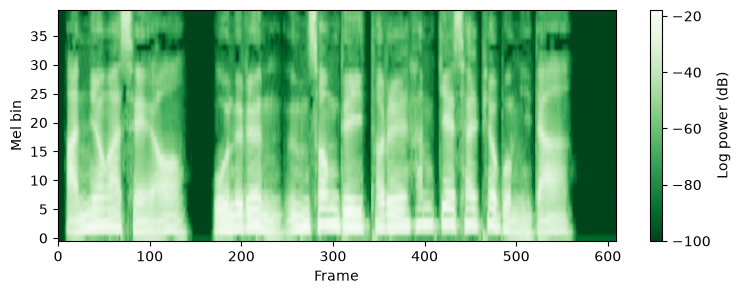

In [5]:
def extract_logmel(sound, cfg=CFG):
    # 파형 → Log-Mel 특징 (프레임 수, 40)
    # 1) STFT: 512샘플 창을 128샘플씩 밀며 주파수 분석
    hz, times, z = stft(sound, fs=cfg['sr'], window='hann',
        nperseg=cfg['n_fft'], noverlap=cfg['n_fft']-cfg['hop'], nfft=cfg['n_fft'],
        boundary=None, padded=False, detrend=False, scaling='spectrum')
    power = np.abs(z)**2                     # 2) 파워
    # 3) Mel 필터 40개 만들기 (HTK 방식)
    to_mel = lambda f: 2595*np.log10(1+f/700)
    to_hz = lambda m: 700*(10**(m/2595)-1)
    edges = to_hz(np.linspace(0, to_mel(cfg['sr']/2), cfg['n_mels']+2))
    filters = np.zeros((cfg['n_mels'], len(hz)))
    for k in range(cfg['n_mels']):
        left, center, right = edges[k:k+3]
        filters[k] = np.maximum(0, np.minimum((hz-left)/(center-left), (right-hz)/(right-center)))
    mel_power = filters @ power              # 4) Mel 대역으로 묶기
    # 5) dB로 바꾸고 (시간, Mel) 순서로 전치
    features = (10*np.log10(np.maximum(mel_power, cfg['floor']))).T.astype('float32')
    assert features.shape == (1+(len(sound)-cfg['n_fft'])//cfg['hop'], cfg['n_mels'])
    return features

# 다시 계산한 특징과 5강 저장값 비교
recomputed = [extract_logmel(read_mono(DATA/r['file'])) for r in rows]
for i, feat in enumerate(recomputed):
    stored = X_raw[i, X_mask[i]]   # 패딩을 뺀 저장값
    assert feat.shape == stored.shape, f"{ids[i]} 프레임 불일치"
    assert np.allclose(feat, stored, atol=1e-4, rtol=1e-5), f"{ids[i]} 특징 설정 불일치"
    print(ids[i], feat.shape, "최대 절대 차이:", float(np.max(np.abs(feat-stored))))
plt.figure(figsize=(9,3))
plt.imshow(recomputed[0].T, origin='lower', aspect='auto', cmap='Greens_r')
plt.xlabel('Frame'); plt.ylabel('Mel bin'); plt.colorbar(label='Log power (dB)'); plt.show()

### Q. `to_mel = lambda f: …`는 왜 `to_mel()` 모양이 아닌가? 그리고 `to_mel(cfg['sr']/2)`에서 왜 샘플링레이트의 절반을 넣나?

값은 이 환경에서 직접 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. 같은 식이 `lesson04_student_practice.ipynb`의 `logmel()`(4강 3-B)과 `05_data_labels_practice.ipynb`의 `logmel()`(3-2)에도 나옵니다.

#### 1. `to_mel = lambda f: 2595*np.log10(1+f/700)` — 함수 정의에 `()`가 없는 이유
- 이 줄은 **함수를 "만들어서" `to_mel`이라는 이름에 담는 대입문**입니다. 호출(`to_mel(…)`)이 아닙니다.
- `lambda f: 식`은 **이름 없는 한 줄짜리 함수**를 만드는 문법입니다. `f`가 매개변수(입력)이고, **콜론(`:`) 뒤의 식이 계산되어 그대로 반환**됩니다(`return`을 쓰지 않음).
- 그래서 아래 두 방법은 **같은 함수**입니다(직접 확인: `to_mel(8000)` 결과가 같음).
```python
to_mel = lambda f: 2595*np.log10(1+f/700)     # lambda 방식 (함수를 변수에 대입)

def to_mel(f):                                  # def 방식 (이름과 ()가 정의 줄에 나타남)
    return 2595*np.log10(1+f/700)
```
| | `def` 방식 | `lambda` 방식 |
|---|---|---|
| 이름 붙이기 | `def 이름(매개변수):` | `이름 = lambda 매개변수: 식` |
| `()` 위치 | 정의 줄에 있음 | 대입의 **왼쪽엔 없고**, 불러 쓸 때 `to_mel(값)`으로 나타남 |
| 본문 | 여러 줄 가능, `return` 필요 | **식 하나만**, `return` 없이 값이 반환됨 |
- **`to_mel`과 `to_mel(8000)`은 다릅니다.** `to_mel`은 함수 자체(`<function <lambda> …>`로 출력됨, `type`은 `function`)이고, `to_mel(8000)`은 그 함수에 8000을 넣어 **계산한 결과**(2840.02…)입니다. 아래 줄에서 `to_mel(cfg['sr']/2)`처럼 `()`로 부를 때 비로소 계산됩니다.
- 이 코드의 `to_hz = lambda m: 700*(10**(m/2595)-1)`는 **반대 방향**(Mel → Hz) 함수입니다. 확인: `to_hz(to_mel(1234.5))`가 다시 `1234.5`로 돌아옵니다.
- 함수 안에서 쓰는 짧은 계산식이라 `def` 대신 `lambda`로 간단히 쓴 것으로 보입니다(제 해석, 추정).

#### 2. `to_mel(cfg['sr']/2)`의 `cfg['sr']/2`는 무엇인가
- `cfg`는 `CFG` 사전이고 `cfg['sr']` = **16000**(샘플링레이트)이므로 `cfg['sr']/2` = **8000.0**입니다(`/`는 나눗셈, 결과는 실수).
- **8000 Hz = 나이퀴스트 주파수**입니다. 샘플링레이트 SR로 기록한 소리가 담을 수 있는 **가장 높은 주파수는 SR÷2**입니다. 수업 앞부분에서 배운 Nyquist(`SR/2`)와 같습니다(03 노트북 20번 셀의 "마지막 칸 = SR÷2"도 같은 내용).
- 이 값이 STFT 결과의 **마지막 주파수 칸**과 일치합니다(직접 확인: `np.fft.rfftfreq(512, 1/16000)`은 `0 … 8000`, 257개). 즉 **우리가 가진 주파수 축은 0~8000 Hz까지**입니다.

#### 3. 그래서 이 줄이 하는 일: `edges = to_hz(np.linspace(0, to_mel(cfg['sr']/2), cfg['n_mels']+2))`
| 순서 | 코드 | 뜻 | 값 (직접 확인) |
|---|---|---|---|
| ① | `to_mel(cfg['sr']/2)` | 주파수 축의 **맨 끝(8000 Hz)을 Mel 눈금의 값으로 변환** | `2840.02` Mel |
| ② | `np.linspace(0, ①, cfg['n_mels']+2)` | Mel 눈금 위에서 **0~2840.02 구간을 같은 간격으로 42개 점**으로 나눔 | 간격 약 69.27 Mel씩 |
| ③ | `to_hz(②)` | 그 42개 점을 다시 **Hz로 되돌림** | `0, 44.4, 91.6, 141.7, …, 6993.7, 7481.4, 8000` |
- **왜 끝값이 8000(나이퀴스트)인가:** Mel 필터 40개가 **STFT가 가진 모든 주파수(0~8000 Hz)를 빠짐없이 덮어야** 하기 때문입니다. 그래서 Mel 눈금의 범위도 `0 ~ to_mel(8000)`으로 잡습니다. 끝값을 이보다 작게(예: 4000 Hz) 잡으면 4000 Hz 위쪽은 필터가 없어 버려지고, 크게 잡으면 존재하지 않는 주파수까지 필터를 배치하게 됩니다.
- **왜 하필 `cfg['sr']/2`로 쓰나:** `16000/2` 대신 설정값에서 계산하므로 **샘플링레이트가 바뀌어도 맞게** 따라갑니다(예: SR 22050이면 끝값이 11025 Hz). 5강 기록의 `preprocessing`과 같은 이유로 설정을 한곳(`CFG`)에서 관리하는 방식입니다.
- **왜 `n_mels + 2` = 42개인가:** 삼각 필터 하나는 `왼쪽 끝 · 중심 · 오른쪽 끝` 3개 점이 필요하고 이웃 필터와 점을 공유하기 때문에, 필터 40개에는 점이 **42개** 필요합니다(바로 아래 `left, center, right = edges[k:k+3]`).
- **왜 Mel 눈금에서 같은 간격으로 나누나:** Mel 눈금은 낮은 주파수를 촘촘하게, 높은 주파수를 넓게 보는 눈금입니다. 그래서 위 `edges`는 낮은 쪽에서 `0 → 44.4 → 91.6 → …`로 **촘촘하고**, 높은 쪽에서 `6993.7 → 7481.4 → 8000`으로 **간격이 넓습니다**(4강 1-D·2교시 그림 참고).
- 한 줄 요약: **`to_mel`은 Hz → Mel 변환 함수이고, `to_mel(cfg['sr']/2)`는 "우리가 가진 주파수 범위의 맨 끝(나이퀴스트 8000 Hz)이 Mel 눈금으로 몇인지"를 구해서, Mel 필터 경계 42개를 0~그 값 사이에 고르게 배치하는 데 쓰는 것입니다.**

### 관찰·직접 적용 · 1-3

그림의 가로축과 세로축이 의미하는 것을 적고, Mel 수만 바꾸었을 때 기존 모델과 호환되지 않는 이유를 설명하세요.

**완료 기준:** 원본·설정이 같으면 저장 특징과 거의 일치합니다. 프레임별 40개의 특징이 생깁니다.

### 내 기록 · 1-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-3 — 먼저 자신의 기록을 작성하세요</summary>

가로는 시간 프레임, 세로는 Mel 대역입니다. n_mels를 바꾸면 입력의 마지막 차원과 특징의 의미가 모두 바뀝니다.

</details>

<a id="practice-1-4"></a>
## 실습 1-4 · 유효 프레임 정규화와 배치 검사 [직접 변경]

**이론 연결:** [HTML 1-4 · 유효 프레임 정규화와 배치 검사](lesson06_theory.html#practice-1-4)

**실행 목적:** 정규화한 유효 구간 평균은 대략 0입니다. 분산이 0인 대역은 정규화 뒤에도 0입니다.

(정규화하면 학습을 보다 더 안정적으로 할 수 있음)

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [6]:
B, T, M = X_raw.shape   # 음성 수, 최대 프레임 수, Mel 수
assert M == CFG['n_mels'] and X_mask.shape == (B,T)
assert np.isfinite(X_raw).all() and np.all(X_lengths > 0)
# 마스크가 '앞은 True, 뒤는 False'인지 확인
expected_mask = np.arange(T)[None,:] < X_lengths[:,None]
assert np.array_equal(X_mask, expected_mask), "오른쪽 패딩 규칙 확인"
assert np.all(X_raw[~X_mask] == 0)
# 실제 프레임만으로 평균·표준편차 계산 (전체 시연 배치를 학습 데이터로 사용)
valid_frames = X_raw[X_mask] # 숫자 indexing + boolean 값 indexing <- 패딩된 부분은 mask로 표시?됨
feature_mean = valid_frames.mean(axis=0).astype('float32')
feature_std = np.maximum(valid_frames.std(axis=0), 1e-5).astype('float32')
# 표준화 후 패딩은 다시 0
X = np.where(X_mask[...,None], (X_raw-feature_mean)/feature_std, 0).astype('float32')
print("X:", X.shape, X.dtype, "mask:", X_mask.shape)
print("유효 구간 평균 절댓값 최대:", float(np.abs(X[X_mask].mean(axis=0)).max()))
print("패딩 비율:", float((~X_mask).mean()))
assert np.isfinite(X).all() and np.all(X[~X_mask] == 0)

X: (3, 1290, 40) float32 mask: (3, 1290)
유효 구간 평균 절댓값 최대: 5.5322680054814555e-06
패딩 비율: 0.30465116279069765


### Q. `X_raw`는 어떻게 `(3, 1290, 40)` 모양이 되었나? (`B, T, M = X_raw.shape`의 B·T·M)

값은 `results/lesson05_batch.npz`와 `data/`의 WAV를 직접 읽어 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 짐작이 맞습니다 — 5강에서 저장한 배열을 읽은 것
- `X_raw = saved['batch'].astype('float32')`의 `saved`는 7번 셀에서 `np.load(RESULTS/'lesson05_batch.npz')`로 연 파일이고, `'batch'`는 그 안에 **5강 실습 4-7에서 저장한 배열의 이름**입니다. 그 저장 코드는 `np.savez(RESULTS/"lesson05_batch.npz", batch=batch, mask=mask, lengths=lengths, label_ids=…, …)`(`05_data_labels_practice.ipynb`)이고, `batch=batch`가 "이름 `batch`로 변수 `batch`를 저장"입니다.
- 그 변수 `batch`는 5강 **실습 3-3의 `make_batch(sequences)`** 가 만든 것입니다(`batch, mask, lengths = make_batch(sequences)`). 즉 이 모양은 npz를 저장할 때가 아니라, **그 전에 `make_batch`가 만들 때** 정해졌고, 저장은 그대로 보관한 것입니다.
- `.astype('float32')`는 32비트 실수로 변환하는 호출입니다. 저장된 배열이 이미 `float32`였으므로(직접 확인) 값은 그대로이고 형식을 확실히 해 두는 안전장치로 보입니다(제 추정).

#### 2. 어떻게 이 모양이 되었나 — 5강 만드는 과정
```text
WAV 3개 (샘플 수 78,336 / 101,760 / 165,504, 모두 16kHz)
   │  3-2 logmel(): STFT → Mel 40개 → 로그 → (Mel 40, 프레임 수)
   │  .T : (프레임 수, Mel 40)     ← 음성마다 프레임 수가 다름
   ▼
sequences = [ (609, 40), (792, 40), (1290, 40) ]   ← 모양이 서로 다른 3개
   │  3-3 make_batch(): 가장 긴 1290에 맞춰 빈 상자 np.zeros((3, 1290, 40)) 를 만들고
   │                     각 음성을 앞쪽에 복사, 나머지는 0으로 남김(패딩)
   ▼
batch  (3, 1290, 40)   +  mask (3, 1290)   +  lengths [609, 792, 1290]
   │  4-7 np.savez(..., batch=batch, mask=mask, lengths=lengths, ...)
   ▼
lesson05_batch.npz  →  (이 노트북) X_raw = saved['batch']
```
- 프레임 수 공식: `(샘플 수 − 512) ÷ 128 + 1`. 직접 확인: 78,336샘플 → 609, 101,760 → 792, 165,504 → **1290**(10.344초).

#### 3. 세 숫자는 각각 어디서 나왔나 (`B, T, M = X_raw.shape`)
| 문자 | 값 | 뜻 | 출처 |
|---|---|---|---|
| **B** (Batch) | 3 | 한 번에 묶은 **음성 개수** | 5강에서 고른 음성 3개(`BATCH_INDICES = [0, 1, 2]`) |
| **T** (Time) | 1290 | **시간 프레임 수의 최댓값** = 가장 긴 음성의 프레임 수 | 가장 긴 음성(10.344초)이 1290프레임이라 모두 1290에 맞춤 |
| **M** (Mel) | 40 | 한 프레임의 **Mel 특징 개수** | `n_mels=40` (`CFG['n_mels']`와 같아야 함: 바로 아래 `assert M == …`) |
- `B, T, M = X_raw.shape`는 모양 튜플 `(3, 1290, 40)`을 세 변수로 **풀어서 받는 것**(언패킹)입니다. 그래서 `B=3, T=1290, M=40`이고, 원소 수는 `3 × 1290 × 40 = 154,800`개입니다(`X_raw.size`로 확인).
- 이 노트북에서 세 문자는 계속 쓰입니다: `X_mask.shape == (B, T)`(마스크는 특징 축이 없음), `np.arange(T)[None,:] < X_lengths[:,None]`.

#### 4. 왜 하필 `(배치, 시간, 특징)`인가
- **하나의 직사각형 배열로 묶기 위해서**입니다. 음성마다 시간 프레임 수가 다르므로(609·792·1290) 그대로는 `np.stack`이 안 되고, 가장 긴 길이에 맞춰 **0으로 채운(패딩)** 뒤 `(음성 수, 최대 시간, 특징)`으로 쌓습니다(5강 3-1·3-3). 어디가 진짜이고 어디가 패딩인지는 `mask`가 알려 줍니다.
- 축 순서는 **약속**입니다. 4강 교재의 "모델 입력 전에 확인할 점"에도 "교재 예제는 모델 입력을 **(배치, 시간, Mel)** 로 가정합니다. 하지만 모든 모델이 같은 순서를 요구하지는 않습니다"라고 적혀 있습니다. 시간 순서를 다루는 Keras 순환 신경망(LSTM 등)은 보통 `(배치, 시간, 특징)`을 입력으로 받습니다 **(일반 지식, 이 노트북에서 확인하지 않음)**. 그래서 5강에서 `(Mel, 시간)`을 `.T`로 `(시간, Mel)`로 바꾼 뒤 배치 축을 붙였습니다.

#### 5. `X_raw`의 값은 어떻게 생겼나 (직접 확인)
- **진짜 구간(마스크 True)** 의 값은 **로그 파워(dB)** 로, 범위가 `-100.0 ~ -15.8`입니다(바닥값 `1e-10`의 로그가 `-100`).
- **패딩 구간(마스크 False)** 은 모두 `0.0`이고, 첫 번째·두 번째 음성의 패딩 프레임은 각각 `681개`, `498개`, 가장 긴 세 번째는 `0개`입니다.
- 눈여겨볼 점: **패딩 `0`이 진짜 값(-100 ~ -15.8)보다 오히려 큰 값**입니다. 0은 "무음"이 아니라 "의미 없는 빈칸 표시"이므로, 패딩을 평균·표준편차에 섞으면 값이 크게 틀어집니다. 바로 아래 셀들이 `X_raw[X_mask]`로 **진짜 프레임만 골라** 평균을 구하고, 표준화한 뒤 패딩을 다시 0으로 맞추는 이유입니다(실제로 패딩 포함/제외 평균 차이 최대가 약 `24.6`이었던 출력 참고).

### 관찰·직접 적용 · 1-4

패딩을 포함한 평균과 제외한 평균의 차이를 아래 셀에서 비교하세요. 그 차이가 실제로 생기는지 숫자로 기록하세요.

**완료 기준:** 정규화한 유효 구간 평균은 대략 0입니다. 분산이 0인 대역은 정규화 뒤에도 0입니다.

In [7]:
# 패딩(0)까지 넣어 계산한 평균과 비교
mean_with_pad = X_raw.mean(axis=(0,1))
print('패딩 포함/제외 평균 차이 최대:',float(np.abs(mean_with_pad-feature_mean).max()))


패딩 포함/제외 평균 차이 최대: 24.607669830322266


### 내 기록 · 1-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 1-4 — 먼저 자신의 기록을 작성하세요</summary>

패딩을 넣은 평균은 실제 녹음 특성 대신 배치의 패딩 양에 영향을 받습니다. 두 평균이 우연히 같더라도 유효 프레임만 쓰는 원칙은 유지합니다.

</details>

(이상 입력 x 음향/성 데이터 전처리 했다)

---

# 2026.10.28(수) 21h~

<a id="practice-2-1"></a>
## 실습 2-1 · 기존 어절 ID 유지와 특수 토큰 추가 [기본 실습]

**이론 연결:** [HTML 2-1 · 기존 어절 ID 유지와 특수 토큰 추가](lesson06_theory.html#practice-2-1)

**실행 목적:** 기존 ID는 동일하고 사전 크기는 2만큼 증가합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [ ]:
def tokenize(text):
    # 5강 규칙: 양끝 공백 제거 → 문장 끝 .!? 제거 → 공백으로 나누기
    return text.strip().rstrip('.!?').split()
assert vocab5.get('<pad>') == 0 and vocab5.get('<unk>') == 1
assert set(vocab5.values()) == set(range(len(vocab5))), "사전 ID는 중복 없는 연속 번호여야 합니다."
assert y5.shape == y5_mask.shape and y5.shape[0] == B
assert np.all(y5[~y5_mask] == 0)
lengths5 = y5_mask.sum(axis=1)
assert np.array_equal(y5_mask, np.arange(y5.shape[1])[None,:] < lengths5[:,None])
inverse5 = {v:k for k,v in vocab5.items()}   # ID → 어절
token_sequences = []
for i, text in enumerate(references):
    seq = y5[i,y5_mask[i]].tolist()          # 패딩을 뺀 정답 ID
    if not seq or any(t not in inverse5 or t in (0,1) for t in seq):
        raise ValueError("시연 정답에 빈 문장·PAD·UNK 또는 잘못된 ID가 있습니다.")
    assert [inverse5[t] for t in seq] == tokenize(text), "정답 ID와 원문 불일치"
    token_sequences.append(seq)
# 기존 ID는 그대로 두고 BOS(begin of sentence)·EOS(end of sentence)만 맨 뒤에 추가
vocab = dict(vocab5)
assert '<bos>' not in vocab and '<eos>' not in vocab
vocab['<bos>'] = len(vocab)
vocab['<eos>'] = len(vocab)
PAD, UNK, BOS, EOS = [vocab[t] for t in ('<pad>','<unk>','<bos>','<eos>')]
inverse = {v:k for k,v in vocab.items()}
V = len(vocab)   # 사전 크기
print("사전 크기:", V, "특수 ID:", PAD, UNK, BOS, EOS)
print("첫 정답 ID:", token_sequences[0])
print("되읽기:", ' '.join(inverse[t] for t in token_sequences[0]))

사전 크기: 35 특수 ID: 0 1 33 34
첫 정답 ID: [2, 3, 4, 5, 6, 7]
되읽기: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다


### Q. `assert vocab5.get('<pad>') == 0 and vocab5.get('<unk>') == 1` — `assert`는 무엇이고 어떻게 동작하나?

값과 동작은 이 환경(Python 3.11)에서 직접 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. `assert`는 이 노트북뿐 아니라 5강(`05_data_labels_practice`의 4-6 등)과 앞 수업에서도 계속 나옵니다.

#### 1. `assert`는 무엇인가 — 함수가 아니라 **키워드(문장)** 입니다
- 맞습니다, `assert`는 **파이썬 키워드**입니다(`keyword.kwlist`에 `'assert'`가 들어 있음을 확인). `print(...)`, `len(...)` 같은 함수가 아니라 `if`, `for`처럼 **문장(statement)** 입니다.
- 모양은 두 가지입니다.
```python
assert 조건              # 조건이 True면 아무 일 없이 지나감 / False면 AssertionError로 멈춤
assert 조건, 메시지       # False일 때 메시지를 함께 보여 줌 (예: assert 1 == 2, "숫자가 다릅니다")
```
- **한 줄 뜻: "이 조건은 반드시 참이어야 한다. 아니면 지금 당장 멈춰라."** 코드가 맞는 상태인지 **스스로 점검(자동 확인)** 하는 용도입니다.

#### 2. 동작 원리
| 조건 | 결과 |
|---|---|
| `True` | **아무것도 출력하지 않고 다음 줄로 진행** (그래서 assert 줄은 성공해도 눈에 안 띔) |
| `False` | **`AssertionError`** 예외를 일으켜 **실행이 멈춤**. 메시지를 적었다면 그 메시지가 함께 표시됨 |
- `assert 조건, 메시지`는 아래 코드와 **같은 뜻**입니다(직접 확인).
```python
if not 조건:
    raise AssertionError(메시지)
```
- `AssertionError`는 오류 종류(예외)의 하나이고 `Exception`을 상속합니다. 노트북에서는 빨간 오류가 나오고 **그 아래 셀들이 실행되지 않습니다.**
- 노트북 셀 안에서 한 셀의 `assert`가 실패하면 **그 줄 앞까지의 변수는 만들어진 상태**이고, 그 줄부터 뒤는 실행되지 않습니다.

#### 3. 이 줄을 풀어 읽기
```python
assert vocab5.get('<pad>') == 0 and vocab5.get('<unk>') == 1
```
| 조각 | 뜻 |
|---|---|
| `vocab5` | 5강에서 저장한 토큰 사전 (어절 → 번호). 7번 셀에서 `record['vocab']`로 만든 것 |
| `vocab5.get('<pad>')` | 사전에서 `'<pad>'`의 번호를 찾음. **없으면 오류 대신 `None`** (앞의 `.get` 설명 셀 참고) |
| `== 0` | 그 번호가 **0인지** 비교 → `True`/`False` |
| `and` | **양쪽이 모두 True여야** True. 왼쪽이 False면 오른쪽은 계산하지 않음(단락 평가) |
| `vocab5.get('<unk>') == 1` | `<unk>`의 번호가 **1인지** 비교 |
| `assert …` | 위 전체가 True가 아니면 멈춤 |
- 연산 순서: `==`가 `and`보다 먼저 계산됩니다(비교 두 개를 각각 계산한 뒤 `and`로 결합). 그래서 괄호 없이 써도 위 뜻이 됩니다.
- 직접 확인: 정상 사전 `{'<pad>': 0, '<unk>': 1, '음성': 2}`에서는 `True`라 조용히 통과합니다. **`<pad>`가 빠진 사전**에서는 `bad.get('<pad>')`가 `None`이라 `None == 0`이 `False` → `AssertionError`가 납니다(이 줄에는 메시지가 없어서 `AssertionError`만 표시됨).

#### 4. 이 줄을 왜 넣었나 (함의)
- **5강의 약속 확인**: 5강 사전은 `<pad>`=0, `<unk>`=1로 **예약**했습니다. 6강의 코드가 이 약속에 기대기 때문에, 5강 기록을 읽어 온 직후 **약속이 지켜졌는지 확인**하는 것입니다.
- 이후 코드가 기대는 곳: 같은 셀 아래의 `assert np.all(y5[~y5_mask] == 0)`(패딩 자리는 0), 2-1의 `PAD, UNK, BOS, EOS = …`, 4-1 손실에서 `tf.not_equal(y_true, PAD)`로 PAD를 빼는 것 등입니다. `<pad>`가 0이 아니거나 `<unk>`가 1이 아니면 **오류 없이 조용히 틀린 결과**가 나올 수 있어서, 시작 지점에서 미리 막아 둡니다.
- 같은 셀의 나머지 `assert`들도 같은 목적(데이터가 기대한 모양·규칙인지 점검)입니다: ID가 중복 없이 연속인지(`set(vocab5.values()) == set(range(len(vocab5)))`), `y5`·`y5_mask`의 모양이 같은지, 마스크가 "앞은 True, 뒤는 False"인지 등.

#### 5. `assert`를 쓸 때 알아 둘 점 (직접 확인한 것 포함)
- **괄호로 감싸면 안 됩니다.** `assert(1 == 2, 'msg')`처럼 쓰면 `(조건, 메시지)`가 **튜플**이 되어 **항상 True로 통과**합니다(파이썬이 `SyntaxWarning: assertion is always true, perhaps remove parentheses?`로 경고). 올바른 모양은 `assert 1 == 2, 'msg'`입니다.
- **`python -O`(최적화 옵션)로 실행하면 `assert`가 통째로 무시**됩니다(직접 확인: `assert False` 뒤의 `print`가 그대로 실행됨, `__debug__`가 `False`). 그래서 **사용자 입력 검사처럼 반드시 지켜야 하는 검사**에는 `assert` 대신 `if … raise ValueError(...)`를 쓰는 것이 관례입니다 **(일반 지식)**. 이 노트북 7번 셀이 `assert`가 아니라 `raise ValueError("중복 ID")`를 쓰는 곳이 그 예입니다. 반면 개발 중에 "내 코드가 맞는 상태인가" 확인하는 용도(이 수업)에는 `assert`가 편합니다.
- **통과해도 "의미까지 맞다"는 뜻은 아닙니다.** 이 줄은 `<pad>`·`<unk>`의 번호만 확인합니다(2-3에서 본 것처럼 모양·범위 검사가 정답 연결까지 보장하지는 않음).
- 실패 원인을 알기 쉽게 하려면 메시지를 붙입니다: `assert 조건, "무엇이 왜 틀렸는지"` (예: 같은 셀의 `assert set(...) == set(range(...)), "사전 ID는 중복 없는 연속 번호여야 합니다."`).

### Q. `y5`는 무엇인가? (1-1에서 `print("y5 = ", y5)`로 찍은 출력의 의미)

값은 이 노트북 7번 셀의 출력과 `results/lesson05_batch.npz`·`lesson05_record.json`을 직접 읽어 확인했습니다.

#### 1. 한 줄 답
- **`y5` = 5강에서 만든 "정답 문장을 어절 번호(ID)로 바꾼 배열"** 입니다. 이름의 `5`는 **5강**의 것이라는 뜻이고(이후 6강에서 만드는 `target` 등과 구별), 7번 셀에서 `y5 = saved['label_ids'].astype('int32')`로 5강 저장 파일(`lesson05_batch.npz`)의 `label_ids`를 읽은 것입니다.
- 모양 `(3, 17)` = **문장 3개 × 가장 긴 문장의 어절 수 17**. 음성 X가 `(3, 1290, 40)`인 것과 같은 방식(길이가 다른 것을 가장 긴 쪽에 맞춰 0으로 채움)입니다(5강 4-4·4-5).

#### 2. 출력 읽는 법
```text
y5 =  [[ 2  3  4  5  6  7  0  0  0  0  0  0  0  0  0  0  0]      ← 첫 번째 문장
       [ 8  9 10 11 12 13 14 15 16 17  0  0  0  0  0  0  0]      ← 두 번째 문장
       [18 19  4 20 21 22 23 24 25 26 27 28 29 30 31 32 17]]     ← 세 번째 문장
```
- **줄 하나 = 문장 하나**, **숫자 하나 = 어절 하나의 번호**(사전 `vocab5`의 번호)입니다. 사전은 `{'<pad>': 0, '<unk>': 1, '안녕하세요.': 2, '오늘은': 3, '음성': 4, …}`(33개).
- **`0`** 은 `<pad>`(길이를 맞추려고 채운 **빈칸**)입니다. 첫 문장은 6개, 두 번째는 10개만 진짜이고 나머지는 0, 세 번째는 17개 전부 진짜입니다.

번호를 사전으로 되읽으면(직접 확인):

| 줄 | 번호 → 어절 |
|---|---|
| 0 | `2 3 4 5 6 7` → 안녕하세요. / 오늘은 / 음성 / 데이터를 / 함께 / 살펴봅니다 |
| 1 | `8 … 17` → 수업이 / 끝나면 / 친구와 / 도서관에 / 가서 / 오늘 / 배운 / 내용을 / 정리하려고 / 합니다 |
| 2 | `18 19 4 20 … 32 17` → 길이가 / 다른 / **음성** / 파일을 / 하나로 / … / 표시해야 / **합니다** |
- 같은 어절은 같은 번호입니다: 0번 줄의 `음성`과 2번 줄의 세 번째 `음성`이 둘 다 `4`, 1번 줄과 2번 줄의 마지막 `합니다`가 둘 다 `17`.

#### 3. `y5_mask`는 무엇인가
```text
y5_mask =  [[ True ×6, False ×11],      ← 0번 문장: 진짜 6개 + 패딩 11개
            [ True ×10, False ×7],      ← 1번 문장: 진짜 10개 + 패딩 7개
            [ True ×17]]                ← 2번 문장: 전부 진짜
```
- `y5_mask`는 `y5`와 **같은 모양 (3, 17)** 의 True/False 배열이고, **True = 진짜 어절, False = 패딩(`<pad>`)** 입니다. 5강의 정답 마스크(`label_mask`)를 그대로 읽은 것입니다.
- 진짜 어절 수 `[6, 10, 17]`은 `y5_mask.sum(axis=1)`로 셉니다(True는 1로 계산됨). 아래 2-1 코드의 `lengths5`가 이 값입니다.

#### 4. 왜 이 배열이 필요한가
- 5강 정답 y를 6강에서 **그대로 이어받아** Decoder 입력(`[BOS]+정답`)과 목표(`정답+[EOS]`)를 만들기 때문입니다(2-1, 2-2). 그래서 2-1 코드가 가장 먼저 "이 `y5`가 약속대로 만들어졌는지" 점검합니다(바로 아래 설명 셀).

### Q. 실습 2-1 코드 한 줄씩 — 나머지 `assert`와 문법 풀이 (`set`, `~`, 불리언 인덱싱, 브로드캐스팅, `any`, 리스트 컴프리헨션)

아래 값과 동작은 이 환경(Python 3.11, NumPy)에서 직접 실행해 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. 먼저 바로 위 두 셀(`assert` 설명, `y5` 설명)을 읽으면 이어집니다.

#### 0. 파이썬 `set`은 순서가 보장되는 집합인가? → **아니요**
- `set`은 **순서가 보장되지 않는** 집합입니다(중복 없는 값의 모음, 번호로 꺼낼 수 없음). 직접 확인: 같은 4단어 집합 `{'음성','모델','공부','실습'}`을 **세 번 다시 실행하면 출력 순서가 매번 달랐습니다**(`['모델','음성','실습','공부']` → `['음성','실습','모델','공부']` → …). 작은 정수 집합은 정렬된 것처럼 보이기도 하지만 우연한 구현 세부사항이라 믿으면 안 됩니다 **(일반 지식)**.
- 반대로 **`dict`는 삽입 순서를 유지**합니다(파이썬 3.7 이상, 직접 확인: `dict(a=1,b=2,c=3)`의 키가 `a, b, c` 순서).
- **집합끼리의 `==`는 순서를 보지 않고 "들어 있는 값이 같은가"만 봅니다.** `{1,2,3} == {3,2,1}`은 `True`, 리스트 `[1,2,3] == [3,2,1]`은 `False`(리스트는 순서가 다르면 다름).
- 그래서 이 코드에서 `set`은 "순서 말고 **내용**이 같은가"를 볼 때 씁니다.

#### 1. 나머지 `assert` 줄
```python
assert set(vocab5.values()) == set(range(len(vocab5))), "사전 ID는 중복 없는 연속 번호여야 합니다."
```
- `vocab5.values()`: 사전의 **값(번호)들** = 0, 1, 2, …, 32(33개, 직접 확인: 최솟값 0, 최댓값 32).
- `range(len(vocab5))` = `range(33)` = 0 ~ 32.
- 둘을 `set`으로 만들어 `==` 비교: **번호들이 정확히 0~32이고, 하나씩이다(중복도 빠진 번호도 없다)** 면 통과. 두 어절이 같은 번호를 쓰면 `set`의 크기가 줄어 통과하지 못하고, 번호가 건너뛰어도(예: 0,1,3) 통과하지 못합니다. 번호를 그대로 **배열의 위치(0부터)**로 쓰는 뒤쪽 계산(예: 출력층 크기 V, Embedding 표)과 어긋나지 않게 하려는 점검입니다.

```python
assert y5.shape == y5_mask.shape and y5.shape[0] == B
```
- `y5.shape == y5_mask.shape`: **모양(튜플) 비교** `(3, 17) == (3, 17)` → True. 정답 배열과 마스크의 모양이 같은지.
- `y5.shape[0] == B`: 첫 번째 값(문장 수) 3이 음성 개수 `B`(= 3)와 같은지. **음성 3개와 정답 3개의 개수가 같다**는 확인입니다.

```python
assert np.all(y5[~y5_mask] == 0)
```
해독 순서(안쪽부터):
1. `~y5_mask`: **`~`는 불리언 배열의 True/False를 뒤집습니다**(NumPy 배열에서). 진짜 자리는 False, **패딩 자리가 True**가 됩니다. 예: 0번 문장의 처음 9칸 `~y5_mask[0]` = `[F F F F F F T T T]`.
2. `y5[~y5_mask]`: **불리언 인덱싱** — `배열[같은 모양의 True/False 배열]`은 **True인 자리의 값만 꺼내 1차원으로 모읍니다.** 즉 **패딩 자리의 값들만** 모은 것이고, 모양은 `(18,)`입니다(전체 `3×17 = 51`칸 − 진짜 33칸 = 패딩 18칸, 직접 확인).
3. `... == 0`: 그 18개 값이 각각 0인지 **원소별 비교** → 18개의 True/False.
4. `np.all(...)`: **전부 True일 때만 True**. 
- 뜻: **"패딩 자리의 값은 모두 0(`<pad>`)이어야 한다."** 직접 확인: 18개가 전부 0이라 통과(`np.all`은 비어 있는 배열에는 True를 돌려줍니다).

```python
lengths5 = y5_mask.sum(axis=1)
assert np.array_equal(y5_mask, np.arange(y5.shape[1])[None,:] < lengths5[:,None])
```
- `y5_mask.sum(axis=1)`: 가로(열) 방향으로 합 → **문장별 진짜 어절 수** `[6, 10, 17]`(True는 1).
- 오른쪽 식은 **"진짜 마스크가 원래 이래야 한다"는 기대 마스크를 만드는 식**입니다. 해독:
  - `y5.shape[1]` = 17(열 수), `np.arange(17)` = `[0, 1, …, 16]`, 모양 `(17,)`.
  - `[None,:]`: 맨 앞에 **빈 축(길이 1)을 추가**해 `(1, 17)`(가로로 긴 행)로 만듭니다(`None`은 `np.newaxis`와 같음). 확인: `(17,)` → `(1, 17)`.
  - `lengths5[:,None]`: `[6, 10, 17]`을 **세로로 세워** `(3, 1)`로 만듭니다(`[[6],[10],[17]]`).
  - `A < B` — 모양이 `(1,17)`과 `(3,1)`이면 NumPy가 자동으로 **브로드캐스팅(모양을 맞춰 확장)** 해서 `(3, 17)`로 비교합니다. 칸 (문장 `i`, 위치 `p`)는 **`p < lengths5[i]`**, 즉 "그 위치가 문장의 길이 안쪽인가?"입니다.
  - 결과(직접 확인): 0번 문장 `[1 1 1 1 1 1 0 0 0 0 …]`(앞 6칸 True), 1번 문장 앞 10칸 True, 2번 문장 17칸 모두 True.
- `np.array_equal(a, b)`: **모양이 같고 모든 값이 같으면 True.** 
- 뜻: **"`y5_mask`가 '앞쪽은 진짜(True), 뒤쪽은 패딩(False)'이고 `lengths5`와 일치한다"**(오른쪽 패딩 규칙). 직접 확인: `True`.

```python
assert '<bos>' not in vocab and '<eos>' not in vocab
```
- `'<bos>' not in vocab`: 사전에서 `in`/`not in`은 **키(어절)** 가 있는지 봅니다. **아직 `<bos>`·`<eos>`가 없다**(이 셀이 처음 추가하는 것)는 확인입니다. 이미 있으면 번호가 중복되거나 덮어써질 수 있어서 막습니다.

#### 2. `for` 반복문 안의 줄들
```python
for i, text in enumerate(references):
    seq = y5[i,y5_mask[i]].tolist()          # 패딩을 뺀 정답 ID
```
- `enumerate(references)`: `(번호 i, 문장 text)` 쌍을 하나씩 → `i = 0, 1, 2`.
- `y5[i, y5_mask[i]]`: **i번째 줄에서 마스크가 True인 자리만** 꺼내는 불리언 인덱싱(위 2번의 한 줄 버전). `.tolist()`로 **파이썬 리스트**로 바꿈. 직접 확인: `i=0` → `[2, 3, 4, 5, 6, 7]`.

```python
if not seq or any(t not in inverse5 or t in (0,1) for t in seq):
    raise ValueError("시연 정답에 빈 문장·PAD·UNK 또는 잘못된 ID가 있습니다.")
```
- 큰 구조는 `if A or B:` (A 또는 B 중 하나라도 참이면 오류).
  - **A = `not seq`**: `seq`가 **빈 리스트**면 `not seq`가 True(빈 리스트는 "거짓"으로 취급). 빈 정답 문장을 막습니다.
  - **B = `any( 조건 for t in seq )`**: 괄호 안의 `조건 for t in seq`는 **제너레이터 식**(리스트 컴프리헨션의 괄호 버전)으로, `seq`의 번호 `t`를 하나씩 꺼내 조건의 True/False를 만들어 냅니다. `any(...)`는 **하나라도 True면 True**(`any([])`는 False).
  - 조건 **`t not in inverse5 or t in (0,1)`**:
    - `t not in inverse5`: `inverse5`는 `{번호: 어절}` 사전이라 `in`은 **번호(키)가 사전에 있나**를 봅니다. 없으면 **존재하지 않는 번호**(잘못된 ID).
    - `t in (0,1)`: **`t`가 `0` 또는 `1`인가**(튜플 `(0,1)` 안에 들어 있나) = `<pad>` 또는 `<unk>`. `t == 0 or t == 1`과 같은 뜻입니다.
- **종합**: "정답이 비었거나, 진짜 어절 자리에 번호가 사전에 없거나, `<pad>`·`<unk>`가 섞여 있으면 오류." 이 시연 정답은 **사전에 있는 진짜 단어만** 있어야 한다는 점검입니다.
- 직접 확인: `[2,3,4,5,6,7]`는 조건이 모두 `False`라 통과, `[2, 0, 4]`는 가운데 `0`에서 `True`가 되어 오류 대상.

```python
assert [inverse5[t] for t in seq] == tokenize(text), "정답 ID와 원문 불일치"
```
- `[inverse5[t] for t in seq]`: 번호들을 **어절로 되돌린 리스트**. `tokenize(text)`: 원문을 같은 규칙으로 나눈 어절 리스트. **리스트 `==`는 순서까지 같아야 True**라서 "저장된 정답 번호가 원문과 똑같이 대응되는가"를 확인합니다(직접 확인: 0번 문장 `['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다']`).

#### 3. 사전을 확장하고 특수 번호를 꺼내는 줄
```python
vocab = dict(vocab5)                    # 복사본 (원본 vocab5는 그대로)
vocab['<bos>'] = len(vocab)             # 33  (지금 33개이므로 다음 번호)
vocab['<eos>'] = len(vocab)             # 34  (이제 34개이므로 다음 번호)
```
- `사전[키] = 값`은 **새 항목 추가**입니다. `len(vocab)`은 추가할 때마다 1씩 늘어서 `<bos>` = 33, `<eos>` = 34가 됩니다. 5강 번호(0~32)는 바뀌지 않습니다.

```python
PAD, UNK, BOS, EOS = [vocab[t] for t in ('<pad>','<unk>','<bos>','<eos>')]
```
- **`vocab[t]`**: 사전에서 키 `t`의 **값(숫자)** 을 꺼냅니다. 맞습니다, 결과는 **숫자(`int`)** 입니다(직접 확인: `vocab['음성']` → `4`, 타입 `int`). 없는 키면 `KeyError`.
- **오른쪽을 감싼 `[ … for t in ( … )]`**: 이것은 평범한 리스트 모양(`[1, 2]`)이 아니라 **리스트 컴프리헨션**(반복하며 리스트를 만드는 문법)입니다. 한 줄씩 풀면:
```python
tmp = []
for t in ('<pad>', '<unk>', '<bos>', '<eos>'):   # 튜플의 이름 4개를 차례로
    tmp.append(vocab[t])                          # 각 이름의 번호를 모음
# tmp = [0, 1, 33, 34]   ← 타입 list, 원소는 모두 int (직접 확인)
```
- **왼쪽 `PAD, UNK, BOS, EOS = [...]`은 언패킹**입니다. 리스트의 4개 값을 **순서대로 네 변수에 하나씩 대입**합니다 → `PAD = 0`, `UNK = 1`, `BOS = 33`, `EOS = 34`(출력 `특수 ID: 0 1 33 34`와 일치). **개수가 맞지 않으면** `ValueError: not enough values to unpack`가 납니다(직접 확인).
- 즉 한 줄의 뜻: **"특수 토큰 4개의 이름으로 번호를 찾아, 읽기 쉬운 변수 이름에 담아 두자."** 이후 `PAD`, `BOS` 등을 변수로 쓰면 숫자(0, 33)를 직접 쓰지 않아도 됩니다.

```python
inverse5 = {v:k for k,v in vocab5.items()}   # 딕셔너리 컴프리헨션: 번호 → 어절
```
- 사전의 `(어절, 번호)` 쌍을 **뒤집어 `(번호, 어절)`** 로 만든 사전입니다. 번호로 어절을 찾을 때 씁니다(앞 `.get` 설명 셀의 `{키: 값 for …}`와 같은 문법). 번호가 중복되면 일부가 덮어써지므로, 맨 위 "번호가 중복 없는 연속"이라는 `assert`가 이 사전의 전제입니다.

### 관찰·직접 적용 · 2-1

5강의 첫 어절 ID가 바뀌지 않았는지 확인하고 BOS·EOS를 추가한 이유를 각각 적으세요.

**완료 기준:** 기존 ID는 동일하고 사전 크기는 2만큼 증가합니다.

### 내 기록 · 2-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-1 — 먼저 자신의 기록을 작성하세요</summary>

BOS는 첫 단어를 예측하기 위한 입력, EOS는 문장 생성이 끝났음을 학습하기 위한 정답입니다.

토큰화 규칙은 문장 **끝**의 부호만 지우므로 `안녕하세요.`처럼 문장 중간의 마침표는 어절에 남습니다. 5강 사전이 이 규칙으로 만들어졌기 때문에 6강에서 규칙을 바꾸면 ID가 맞지 않습니다.

</details>

<a id="practice-2-2"></a>
## 실습 2-2 · Decoder 입력과 한 칸 이동한 정답 [기본 실습]

**이론 연결:** [HTML 2-2 · Decoder 입력과 한 칸 이동한 정답](lesson06_theory.html#practice-2-2)

**실행 목적:** 목표의 마지막 유효 토큰은 EOS이며 입력·정답은 한 칸 어긋납니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [ ]:
def make_decoder_batch(sequences):
    # 정답 → Decoder 입력([BOS]+정답), 목표(정답+[EOS]), PAD 아닌 위치
    # [map(len, sequences)] map(함수, 반복가능한것) = 목록의 각 원소에 함수를 하나씩 적용한 결과를 차례로 내주는 도구입니다.
    #   여기서는 정답 목록 sequences의 각 문장(리스트)에 len을 적용 → 문장별 토큰 수 6, 10, 17 (직접 확인).
    #   map()은 바로 리스트를 만들지 않고 '필요할 때 하나씩 꺼내 주는 map 객체'를 돌려줍니다. 한 번 꺼내 쓰면 소진되고,
    #   값을 보려면 list(map(len, sequences)) → [6, 10, 17]처럼 감쌉니다.
    #   max(...)는 그 중 가장 큰 값 17, 거기에 +1(BOS 또는 EOS 자리) = 18 → 가장 긴 정답에 맞춘 폭입니다.
    #   같은 뜻의 다른 표현: max(len(seq) for seq in sequences) + 1
    width = max(map(len, sequences)) + 1
    dec_in = np.full((len(sequences),width), PAD, dtype=np.int32)
    target = np.full_like(dec_in, PAD)
    for i, seq in enumerate(sequences):
        n = len(seq)+1
        dec_in[i,:n] = [BOS]+seq     # 예: [BOS, A, B, C]
        target[i,:n] = seq+[EOS]     # 예: [A, B, C, EOS]
    return dec_in, target, target != PAD

decoder_in, decoder_target, target_mask = make_decoder_batch(token_sequences)
U = decoder_in.shape[1]   # 출력 위치 수
for i in range(B):
    n = len(token_sequences[i])+1
    assert decoder_in[i,0] == BOS and decoder_target[i,n-1] == EOS
    assert np.array_equal(decoder_in[i,1:n], decoder_target[i,:n-1])   # 한 칸 어긋남
    assert target_mask[i].sum() == n
print("decoder_in:", decoder_in.shape, "target:", decoder_target.shape)
print("첫 입력:", [inverse[int(t)] for t in decoder_in[0]])
print("첫 정답:", [inverse[int(t)] for t in decoder_target[0]])

decoder_in: (3, 18) target: (3, 18)
첫 입력: ['<bos>', '안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
첫 정답: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


### Q. `np.full`과 `np.full_like`은 무엇인가? (2-2 `make_decoder_batch`의 `dec_in = np.full(...)`, `target = np.full_like(...)`)

값은 이 환경(NumPy)에서 직접 실행해 확인했습니다. 앞의 `map(len, sequences)` 주석과 이어서 읽으면 됩니다.

#### 1. 한 줄 뜻
- **`np.full(모양, 채울값)`** = **지정한 모양의 배열을 만들어, 모든 칸을 같은 값으로 채운다.**
- **`np.full_like(배열, 채울값)`** = **다른 배열과 "같은 모양·같은 자료형"의 새 배열을 만들어 모든 칸을 같은 값으로 채운다.** (`_like` = "~와 같은 모양으로")

| 함수 | 모양을 정하는 방법 | 자료형 |
|---|---|---|
| `np.full(shape, fill_value, dtype=…)` | **직접** 적음 (튜플, 예: `(3, 18)`) | `dtype`을 안 쓰면 **채울 값에서 추정** (아래 확인) |
| `np.full_like(a, fill_value)` | **배열 `a`의 모양을 그대로 복사** | **`a`의 자료형을 그대로 따라감** |

#### 2. 이 코드에서
```python
width = max(map(len, sequences)) + 1                                  # 18
dec_in = np.full((len(sequences), width), PAD, dtype=np.int32)         # ① (3, 18)을 PAD(=0)로 가득 채움
target = np.full_like(dec_in, PAD)                                     # ② dec_in과 같은 (3, 18), int32, PAD로 가득
```
- ① `np.full((3, 18), 0, dtype=np.int32)`: **모양은 튜플 `(행 수, 열 수)`** 로 적습니다(`len(sequences)` = 3문장, `width` = 18). 채울 값은 `PAD`(0). `dtype=np.int32`로 **32비트 정수**를 지정했습니다(Decoder 입력은 번호이므로 정수).
- ② `np.full_like(dec_in, PAD)`: `dec_in`을 보고 **같은 `(3, 18)`, 같은 `int32`** 로 만들고 `PAD`로 채웁니다. 그래서 모양과 `dtype`을 다시 적을 필요가 없습니다(직접 확인: 결과가 `(3, 18)`, `int32`).
- **왜 "PAD로 먼저 가득 채우고" 시작하나?** 아래 반복문이 문장마다 **앞쪽 `n`칸만** 진짜 값으로 덮어씁니다.
```python
dec_in[i,:n] = [BOS]+seq     # 앞 n칸에 BOS+정답을 덮어쓰기
target[i,:n] = seq+[EOS]     # 앞 n칸에 정답+EOS를 덮어쓰기
```
  **덮어쓰지 않은 나머지 칸은 처음 채워 둔 `PAD`로 남아** 자동으로 "뒤쪽 패딩"이 됩니다. 그래서 "빈 상자를 PAD로 만든 뒤 진짜 값만 앞에 채워 넣기" 방식입니다(5강 `np.zeros` + 앞쪽 대입과 같은 패턴인데, 패딩 값이 0이 아닐 수도 있어서 `np.full`을 씁니다. 이 노트북에서는 `PAD`가 0이라 결과는 같습니다).
- 작은 예(직접 확인): 정답 `[[2,3,4],[2,1]]`, `BOS=33`, `EOS=34`, `PAD=0`이면 `width = 4`이고 반복문 뒤에
```text
dec_in = [[33  2  3  4]          target = [[ 2  3  4 34]
          [33  2  1  0]]                   [ 2  1 34  0]]
```
  짧은 둘째 문장의 마지막 칸이 `0`(PAD)로 남습니다.

#### 3. 알아 둘 점 (직접 확인)
- **`dtype`을 안 쓰면 채울 값에서 정해집니다.** `np.full((2,3), 7)` → `int64`, `np.full((2,3), 7.0)` → `float64`, `np.full((2,3), 7, dtype=np.int32)` → `int32`. 그래서 번호 배열처럼 **자료형이 중요할 때는 `dtype`을 직접 씁니다**(뒤 `check_training_arrays`가 `dec_in.dtype == np.int32`를 검사).
- **`full_like`는 기본적으로 원본의 `dtype`을 따라갑니다.** `float32` 배열을 주고 `full_like(a, 5)`를 하면 `float32` 결과(`[[5. 5.]...]`)입니다. 다른 `dtype`을 원하면 `np.full_like(a, 7, dtype=np.float64)`처럼 씁니다.
- **모양은 튜플입니다.** 2차원은 `(행, 열)`로 괄호를 한 번 더 씁니다. `np.full(2, 3, PAD)`처럼 쓰면 세 번째 자리가 `dtype`으로 읽혀 오류(`Cannot interpret '0' as a data type`)가 나고, 1차원은 `np.full(3, 0)` → `[0 0 0]`입니다.
- 친척 함수: `np.zeros(shape)`(0으로 채움) = `np.full(shape, 0)`, `np.ones(shape)`(1로 채움), `np.zeros_like(a)`, `np.ones_like(a)`. `np.full`은 **0이나 1이 아닌 값**(여기서는 `PAD`)으로 채울 때 씁니다.

### 관찰·직접 적용 · 2-2

첫 문장의 각 위치를 ‘입력 토큰 → 목표 토큰’으로 나란히 출력하고, 마지막 유효 위치의 정답을 확인하세요.

**완료 기준:** 목표의 마지막 유효 토큰은 EOS이며 입력·정답은 한 칸 어긋납니다.

In [10]:
# 위치별 '입력 → 맞혀야 할 토큰'
for pos in range(int(target_mask[0].sum())):
    print(pos, inverse[int(decoder_in[0,pos])], '→', inverse[int(decoder_target[0,pos])])


0 <bos> → 안녕하세요.
1 안녕하세요. → 오늘은
2 오늘은 → 음성
3 음성 → 데이터를
4 데이터를 → 함께
5 함께 → 살펴봅니다
6 살펴봅니다 → <eos>


### 내 기록 · 2-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-2 — 먼저 자신의 기록을 작성하세요</summary>

입력과 정답을 동일하게 만들면 현재 토큰 복사 문제가 되므로 다음 토큰 예측을 배울 수 없습니다.

</details>

<a id="practice-2-3"></a>
## 실습 2-3 · 학습 데이터 계약과 오류 찾기 [직접 변경] = 학습 직전에 확인하는 내용, 

**이론 연결:** [HTML 2-3 · 학습 데이터 계약과 오류 찾기](lesson06_theory.html#practice-2-3)

**실행 목적:** V는 사전 크기이므로 유효 ID의 최댓값은 V-1입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [ ]:
def check_training_arrays(audio, audio_mask, dec_in, target, vocab_size):
    # 학습 직전 배열의 모양·자료형·값 범위 점검
    assert audio.ndim == 3 and audio.shape[2] == CFG['n_mels'] # 음성 배열 = 3차원 = batch 크기 + timeline 길이/크기 + 40(log-Mel의 길이), audio의 shape은 2차원
    assert audio.shape[:2] == audio_mask.shape # 음성의 특징 = 음성 mask batch/frame 수
    assert dec_in.shape == target.shape and len(audio) == len(target) # decoder 입력과 정답의 shapes 동일한지, 입력의 크기 = 정답 문장의 수
    assert audio.dtype == np.float32 and audio_mask.dtype == bool
    assert dec_in.dtype == np.int32 and target.dtype == np.int32 # decoder 입력 및 정답의 토큰 id가 32비트 정수형인지
    assert np.isfinite(audio).all() and audio_mask.any(axis=1).all() # 음성 특징에 NaN, 무한대 등이 없음 + 각 음성의 실제 frame이 1개 이상 있음
    assert np.all((dec_in >= 0) & (dec_in < vocab_size)), "입력 ID 범위 오류"
    assert np.all((target >= 0) & (target < vocab_size)), "정답 ID 범위 오류"
    assert np.all(dec_in[:,0] == BOS) # 모든 문장의 decoder 첫번째 입력 = BOS
    assert (target != PAD).any(axis=1).all() # target = 모든 문장의 PAD 아님, 실제 정답 토큰이 1개 이상 있음
    return True
print("배열 계약 통과:", check_training_arrays(X, X_mask, decoder_in, decoder_target, V))
# 복사본에 범위 밖 ID(V)를 넣어 검사가 잡는지 확인
bad_in = decoder_in.copy()
bad_in[0,0] = V # 존재하지 않는 ID 대입/입력
print(f"decoder_in {decoder_in} vs bad_in[0,0] {bad_in[0,0]}")
try:
    check_training_arrays(X, X_mask, bad_in, decoder_target, V)
except AssertionError as error:
    print("예상한 검사 실패:", error)

배열 계약 통과: True
decoder_in [[33  2  3  4  5  6  7  0  0  0  0  0  0  0  0  0  0  0]
 [33  8  9 10 11 12 13 14 15 16 17  0  0  0  0  0  0  0]
 [33 18 19  4 20 21 22 23 24 25 26 27 28 29 30 31 32 17]] vs bad_in[0,0] 35
예상한 검사 실패: 입력 ID 범위 오류


### 관찰·직접 적용 · 2-3

다른 복사본에서 정답 행을 뒤집어 보세요. 모양 검사만으로 정답 연결 오류를 찾을 수 있는지 판단하세요.

**완료 기준:** V는 사전 크기이므로 유효 ID의 최댓값은 V-1입니다.

In [12]:
# 정답 행 순서만 뒤집은 복사본 → 모양 검사는 통과할까?
reversed_target = decoder_target[::-1].copy()
print('행을 바꾼 정답도 모양 검사 통과:',check_training_arrays(X,X_mask,decoder_in,reversed_target,V))
print('이 출력은 ID·의미 연결이 맞다는 뜻이 아닙니다.')


행을 바꾼 정답도 모양 검사 통과: True
이 출력은 ID·의미 연결이 맞다는 뜻이 아닙니다.


### 내 기록 · 2-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-3 — 먼저 자신의 기록을 작성하세요</summary>

행을 뒤집으면 모양이 같아 검사를 통과할 수 있습니다. ID와 정답 원문 대조는 배열 모양 검사와 다른 책임입니다.

</details>

<a id="practice-2-4"></a>
## 실습 2-4 · 한 자료를 끝까지 추적하기 [직접 변경]

**이론 연결:** [HTML 2-4 · 한 자료를 끝까지 추적하기](lesson06_theory.html#practice-2-4)

**실행 목적:** 선택 ID의 정답과 토큰열이 연결되며, X의 프레임 수와 정답 토큰 수는 다릅니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [ ]:
ROW = 0  # 다른 행으로 바꿔 추적하세요.
assert 0 <= ROW < B
n = int(target_mask[ROW].sum()) # 실제 정답 위치 수? = 전체 단어 사전 문장 수 + EOS
print("n:", n)
print("ID:", ids[ROW], "파일(경로)):", rows[ROW]['file'])
print("원문/실제 정답 문장:", references[ROW])
print("패딩 전 X:", X[ROW,X_mask[ROW]].shape) # 패딩 제외한 실제 frames 수 맟 Mel 특징 수
for position in range(n):
    print(position, inverse[int(decoder_in[ROW,position])], '→', inverse[int(decoder_target[ROW,position])])
print("전체 음성 시간 칸:", T, "전체 출력 위치:", U)

n: 7
ID: 1272-128104-0001 파일: speech/1272-128104-0001.wav
원문: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다.
패딩 전 X: (609, 40)
0 <bos> → 안녕하세요.
1 안녕하세요. → 오늘은
2 오늘은 → 음성
3 음성 → 데이터를
4 데이터를 → 함께
5 함께 → 살펴봅니다
6 살펴봅니다 → <eos>
전체 음성 시간 칸: 1290 전체 출력 위치: 18


### 관찰·직접 적용 · 2-4

다른 ID를 선택하여 데이터 흐름을 설명하세요. T와 U가 달라도 정상인 이유를 적으세요.

**완료 기준:** 선택 ID의 정답과 토큰열이 연결되며, X의 프레임 수와 정답 토큰 수는 다릅니다.

### 내 기록 · 2-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-4 — 먼저 자신의 기록을 작성하세요</summary>

한 프레임이 한 어절에 대응하지 않습니다. 여러 음성 프레임에 걸친 발화 정보를 모델이 처리해 토큰을 예측합니다.

</details>

<a id="practice-2-S"></a>
## 실습 2-S · 사전 밖 어절과 추론의 한계 [자율실습]

**이론 연결:** [HTML 2-S · 사전 밖 어절과 추론의 한계](lesson06_theory.html#practice-2-S)

**실행 목적:** 기존 어절은 기존 ID, 미등록 어절은 1입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [14]:
NEW_SENTENCE = '새로운 장비를 점검합니다'   # 원하는 문장으로 바꿔 보세요.
new_words = tokenize(NEW_SENTENCE)
new_ids = [vocab.get(word,UNK) for word in new_words]   # 없으면 UNK
for word, token_id in zip(new_words,new_ids):
    print(word,'→',token_id,'→',inverse[token_id])
unknown_rate = sum(t == UNK for t in new_ids)/len(new_ids) if new_ids else 0
print('미등록 어절 비율:',unknown_rate)

새로운 → 1 → <unk>
장비를 → 1 → <unk>
점검합니다 → 1 → <unk>
미등록 어절 비율: 1.0


### 관찰·직접 적용 · 2-S

기존 정답의 일부 어절과 사전에 없는 어절을 섞은 문장으로 바꾸세요. 사전만 수정하면 되는지 설명하세요.

**완료 기준:** 기존 어절은 기존 ID, 미등록 어절은 1입니다.

### 내 기록 · 2-S

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 2-S — 먼저 자신의 기록을 작성하세요</summary>

Embedding 행 수와 Dense 출력 수가 V에 맞춰져 있습니다. 사전의 번호·크기 변경은 모델까지 다시 설계하거나 학습하는 문제입니다.

</details>

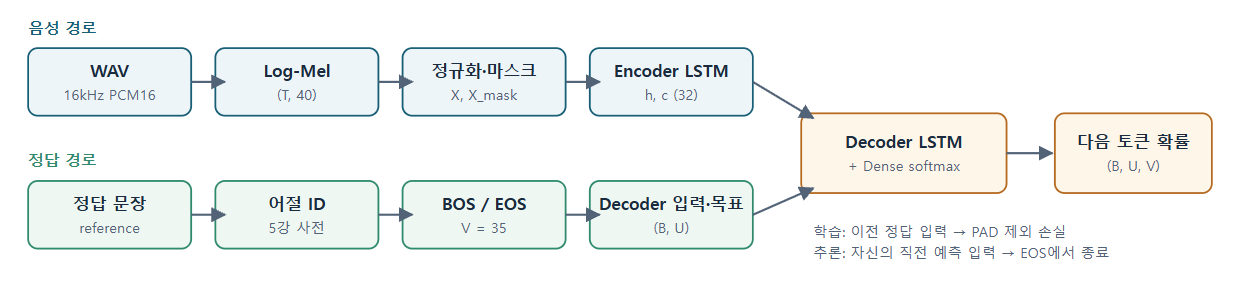

<a id="practice-3-1"></a>
## 실습 3-1 · Encoder 구성과 상태 벡터 [기본 실습]

**이론 연결:** [HTML 3-1 · Encoder 구성과 상태 벡터](lesson06_theory.html#practice-3-1)

**실행 목적:** 입력 (1,T,40)이 상태 h·c 각각 (1,32)로 바뀝니다. 이 Encoder는 `go_backwards=True`로 음성을 **끝에서 앞으로** 읽습니다. 이유는 HTML 3-1과 4-S에서 확인합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [15]:
UNITS = 32       # LSTM 상태 크기
EMBED_DIM = 24   # 토큰 벡터 크기
# 입력 1: 음성 특징 (길이 자유, 프레임당 40개)
audio_input = keras.Input(shape=(None, CFG['n_mels']), dtype='float32', name='audio')
# 입력 2: 음성 마스크 (True인 프레임만 읽음)
audio_mask_input = keras.Input(shape=(None,), dtype='bool', name='audio_mask')
# Encoder: 음성을 끝까지 읽고 마지막 상태 h, c를 돌려줌
# go_backwards=True: 음성을 끝에서 앞으로 읽음 → 마지막 상태에 문장 앞부분 정보가 남음
encoder_lstm = keras.layers.LSTM(UNITS, return_state=True, go_backwards=True, name='encoder_lstm')
encoder_output, state_h, state_c = encoder_lstm(audio_input, mask=audio_mask_input)
encoder_model = keras.Model([audio_input,audio_mask_input], [state_h,state_c], name='encoder')
h0, c0 = encoder_model([X[:1], X_mask[:1]], training=False)   # 첫 음성으로 시험
print("Encoder h:", h0.shape, "c:", c0.shape)
encoder_model.summary()

Encoder h: (1, 32) c: (1, 32)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio (InputLayer)  │ (None, None, 40)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ audio_mask          │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 32),      │      9,344 │ audio[0][0],      │
│                     │ (None, 32),       │            │ audio_mask[0][0]  │
│                     │ (None, 32)]       │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,344 (36.50 KB)

 Trainable params: 9,344 (36.50 KB)

 Non-trainable params: 0 (0.00 B)

### 관찰·직접 적용 · 3-1

units를 늘리면 어떤 배열의 마지막 차원과 파라미터 수가 바뀔지 예상하세요. 기본 실행에서는 32를 유지합니다.

**완료 기준:** 입력 (1,T,40)이 상태 h·c 각각 (1,32)로 바뀝니다.

### 내 기록 · 3-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-1 — 먼저 자신의 기록을 작성하세요</summary>

h와 c는 음성에서 계산한 정보입니다. 고정 길이 상태를 만들기 때문에 Decoder의 토큰 길이는 입력 프레임 수와 같을 필요가 없습니다.

LSTM의 마지막 상태는 마지막에 읽은 부분의 영향을 가장 크게 받습니다. 실습 WAV는 모두 끝에 0.4~0.8초의 완전한 무음이 있어 정방향으로 읽으면 세 음성의 마지막 상태가 같아집니다. 거꾸로 읽으면 마지막에 읽는 부분이 문장의 시작이므로 음성마다 상태가 달라집니다.

</details>

## 📌 따라잡기 — 3교시(21h~) 실습 2-1 ~ 3-1 한 장 요약

**주의:** 이 요약은 **이 노트북의 코드와 출력**을 보고 정리한 것입니다. 강사님이 수업에서 어떻게 설명하셨는지는 듣지 못해 확인하지 못했고, 일반 상식은 **(일반 지식)**으로 표시했습니다. 수업 영상으로 보완하세요.

### 1. 읽는 순서 (오늘 따라잡기)
1. **먼저 위에서부터 셀을 실행**해서 변수(`X`, `X_mask`, `vocab5`, …)를 살려 둡니다. 이후 셀이 앞 변수를 씁니다.
2. 아래 표로 흐름을 잡고, **2-2(교사 강요)를 가장 먼저** 이해합니다. 6강의 핵심 개념이고 4교시까지 이어집니다.
3. 모든 줄을 이해하려 하지 말고 **2-2 → 2-3 → 3-1** 순서로 "입력이 어떻게 만들어져 어디로 들어가는가"만 잡습니다.

### 2. 한 장 요약
| 실습 | 한 줄 | 출력에서 확인되는 것 |
|---|---|---|
| **2-1** | 5강 사전(33개)을 **그대로 두고** `<bos>`, `<eos>`만 **맨 뒤에 추가** | `사전 크기: 35`, 특수 ID: `<pad>`=0, `<unk>`=1, `<bos>`=33, `<eos>`=34. 5강 ID(`안녕하세요.`=2 …)는 안 바뀜 → 5강 정답 y를 그대로 쓸 수 있음 |
| **2-2** | Decoder용 학습 데이터 만들기. **입력 = `[BOS] + 정답`, 목표 = `정답 + [EOS]`** 라서 한 칸 어긋남 | `decoder_in: (3, 18)`, `target: (3, 18)`. 위치별 `<bos>→안녕하세요.`, `안녕하세요.→오늘은`, …, `살펴봅니다→<eos>` |
| **2-3** | 학습 직전 점검 함수: 모양, dtype, ID 범위(0 이상 V 미만), 첫 토큰이 BOS인지 | ID에 V(35)를 넣으면 `입력 ID 범위 오류`로 잡힘. 그런데 **정답 행을 뒤집어도 이 검사는 통과**함 → 모양·범위 검사만으로는 "정답 연결이 맞는지"를 알 수 없음 |
| **2-4** | 한 자료를 끝까지 추적 | ID `…0001` → X `(609, 40)` → 정답 토큰 6개 + EOS = 7개. 전체 `T=1290`, `U=18`이 서로 달라도 정상 |
| **2-S** | 사전에 없는 어절은 `<unk>`(1) | `새로운 장비를 점검합니다` → 3개 모두 `1`, 미등록 비율 `1.0` |
| **3-1** | Encoder: 음성을 LSTM으로 끝까지 읽고 **마지막 상태 h, c**를 뽑음 | 입력 `(1, T, 40)` → h, c 각각 `(1, 32)`. `go_backwards=True`라 음성을 **끝에서 앞으로** 읽음 |

### 3. 핵심 개념 풀이
- **BOS / EOS (2-1)**: `<bos>`는 "문장이 시작된다"는 시작 신호, `<eos>`는 "문장이 끝났다"는 끝 신호입니다 **(일반 지식)**. 사전 뒤에 붙인 이유는 **기존 번호를 바꾸지 않기 위해서**입니다(5강 y와 호환).
- **한 칸 어긋난 입력과 목표 (2-2, 교사 강요)**: 각 위치에서 "지금까지의 정답"을 입력으로 주고 **바로 다음 토큰**을 맞히게 합니다. 예: 위치 1은 입력 `안녕하세요.` → 맞혀야 할 것 `오늘은`. 마지막 위치의 목표가 `<eos>`라서 모델이 "언제 끝내는지"도 배웁니다. 4교시의 학습·예측 비교로 이어집니다(제 이해이며 수업 설명은 확인하지 못함).
- **모양 검사의 한계 (2-3)**: 5강의 "X·y의 모양이 맞아도 **ID 순서 검사**가 필요한 이유"와 같은 얘기입니다. 행 순서를 뒤집어도 모양·범위는 그대로라 통과합니다.
- **T와 U가 달라도 되는 이유 (2-4)**: T=음성 시간 프레임 수(8ms 단위), U=정답 토큰 위치 수(어절 단위)라서 **단위가 다릅니다**. 같은 행(ID)끼리만 짝이면 됩니다.
- **2-S 질문 "사전만 수정하면 되는지"**: 제 이해로는 **아닙니다**. 단어를 추가하면 사전 크기 V가 바뀌어 모델의 **출력층 크기**도 바뀌고, 새 단어를 맞히도록 **다시 학습**해야 합니다 **(일반 지식, 강사님 설명은 확인하지 못함)**. 이 노트북에서는 모르는 어절을 `<unk>`로 처리해 자리를 남깁니다.
- **`go_backwards=True` (3-1)**: 셀 주석 그대로 "음성을 끝에서 앞으로 읽음 → 마지막 상태에 문장 앞부분 정보가 남음"입니다. 노트북 안내문도 이유를 "HTML 3-1과 4-S에서 확인"한다고 적고 있어 **더 자세한 설명은 수업 영상·4-S에서 확인**해야 합니다.

### 4. 앞 수업과 이어지는 곳
- 2-1의 `vocab5`는 5강에서 저장한 사전을 `record['vocab']`에서 꺼낸 것(앞의 "Q. `record['vocab']`은 무엇인가?" 셀).
- 3-1의 `X`, `X_mask`는 1-4에서 **패딩을 뺀 진짜 프레임으로 표준화**한 배열입니다(앞의 "Q. `X_raw`는 어떻게 `(3, 1290, 40)`…" 셀).
- 2-3은 5강 마무리 문제 7번("같은 행의 ID 순서는 반드시 일치해야 하는 이유")과 연결됩니다.

# 2026.10.28(수) 22h~

<a id="practice-3-2"></a>
## 실습 3-2 · Embedding과 Decoder 연결 [기본 실습]

**이론 연결:** [HTML 3-2 · Embedding과 Decoder 연결](lesson06_theory.html#practice-3-2)

**실행 목적:** 모델에는 세 입력과 한 출력이 있으며 출력 마지막 축은 사전 크기입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [16]:
# 입력 3: Decoder 토큰 ID
token_input = keras.Input(shape=(None,), dtype='int32', name='decoder_tokens')
embedding_layer = keras.layers.Embedding(V, EMBED_DIM, mask_zero=False, name='token_embedding') # embedding vector, 단어들 간의 관계 정리
decoder_lstm = keras.layers.LSTM(UNITS, return_sequences=True, return_state=True, name='decoder_lstm') # return_sequences True = 모든 위치마다 값 뽑아냄
output_layer = keras.layers.Dense(V, activation='softmax', name='token_probabilities')
embedded = embedding_layer(token_input)                                         # (B, U, 24)
decoder_states, _, _ = decoder_lstm(embedded, initial_state=[state_h,state_c])  # (B, U, 32), 음성 상태로 시작
probabilities = output_layer(decoder_states)                                    # (B, U, V)
model = keras.Model([audio_input,audio_mask_input,token_input], probabilities, name='speech_seq2seq')
model.summary()
print("모델 입력 이름:", [t.name for t in model.inputs])

Model: "speech_seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_tokens      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ audio (InputLayer)  │ (None, None, 40)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ audio_mask          │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedding     │ (None, None, 24)  │        840 │ decoder_tokens[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 32),      │      9,344 │ audio[0][0],      │
│                     │ (None, 32),       │            │ audio_mask[0][0]  │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │      7,296 │ token_embedding[… │
│                     │ 32), (None, 32),  │            │ encoder_lstm[0][… │
│                     │ (None, 32)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_probabilities │ (None, None, 35)  │      1,155 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,635 (72.79 KB)

 Trainable params: 18,635 (72.79 KB)

 Non-trainable params: 0 (0.00 B)

모델 입력 이름: ['audio', 'audio_mask', 'decoder_tokens']


### 관찰·직접 적용 · 3-2

Embedding·LSTM·Dense의 입력과 출력 모양을 표로 적고, Dense 출력 차원이 V인 이유를 설명하세요.

**완료 기준:** 모델에는 세 입력과 한 출력이 있으며 출력 마지막 축은 사전 크기입니다.

### 내 기록 · 3-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-2 — 먼저 자신의 기록을 작성하세요</summary>

출력은 정답 ID 하나가 아니라 후보 전체의 확률입니다. 나중에 argmax로 한 후보를 선택합니다.

</details>

## POP QUIZ — Keras 모델에서 순전파(forward)와 역전파(backward)의 의미와 용도

수치는 이 노트북의 3-3·4-2 출력과, 아래에 적은 **작은 예제(Dense 1개, 샘플 3개)를 이 환경(TensorFlow 2.16)에서 직접 실행한 값**입니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. 강사님이 기대하시는 표현은 확인하지 못했습니다.

### 1. 한 줄 답
| | 의미 | 용도 |
|---|---|---|
| **순전파** (forward propagation) | **입력 → 층들을 차례로 통과 → 출력(예측)** 을 계산하는 방향의 계산 | 예측값을 얻는다. 손실을 계산하는 재료가 된다. **학습과 추론(예측) 둘 다에 쓴다** |
| **역전파** (backpropagation) | **손실이 가중치에 얼마나 민감한지(기울기)를 출력 쪽에서 입력 쪽으로 거꾸로** 계산하는 방향의 계산 | **학습**에서 가중치를 어느 방향으로 얼마나 고칠지 알려 준다. **추론에는 쓰지 않는다** |

- 순서로 보면 한 번의 학습 단계는 **① 순전파로 예측 → ② 손실 계산(정답과의 차이) → ③ 역전파로 기울기 계산 → ④ 옵티마이저가 가중치 갱신**입니다. 이 네 단계를 batch(또는 epoch)마다 반복하는 것이 학습입니다 **(일반 지식)**.
- 흔한 오해: **역전파가 가중치를 직접 고치는 것은 아닙니다.** 역전파는 "기울기"를 구해 주고, 실제로 가중치를 바꾸는 것은 **옵티마이저**(이 노트북에서는 Adam)입니다.

### 2. Keras에서는 어디에 해당하나
| 하는 일 | Keras 코드 | 이 노트북의 위치 |
|---|---|---|
| 순전파만 실행 | `model(입력)` 또는 `model.predict(입력)` | **실습 3-3**의 `before_probs = model(train_inputs, training=False)` → `(3, 18, 35)` |
| 손실 계산 | `compile(loss=…)`에 지정한 손실 | 4-1 `masked_token_loss` |
| 역전파 + 가중치 갱신 | `model.fit(...)` 안에서 **자동으로** 수행(내부적으로 기울기 계산) | **실습 4-2**의 `model.fit(train_ds, epochs=EPOCHS …)` |
- `compile(optimizer=Adam(…), loss=…)`는 "손실을 무엇으로 잴지"와 "기울기로 가중치를 어떻게 고칠지"를 정해 두는 설정이고, `fit`이 그 설정으로 ①~④를 반복합니다.
- 직접 기울기를 보고 싶으면 `tf.GradientTape`로 순전파를 기록한 뒤 `tape.gradient(손실, 가중치)`를 호출합니다 **(일반 지식)**. 아래 3번 예제가 이것입니다.

### 3. 숫자로 보는 작은 예제 (직접 실행해 확인)
가중치 `w` 하나짜리 모델 `예측 = w × 입력`, 입력 `[1, 2, 3]`, 정답 `[2, 4, 6]`(정답은 `w = 2`), 처음 `w = 0.5`, 손실은 평균제곱오차(MSE), 학습률 0.05.

| 단계 | 계산 | 결과 |
|---|---|---|
| ① 순전파 | `0.5 × [1, 2, 3]` | 예측 `[0.5, 1.0, 1.5]` |
| ② 손실 | `mean((예측 − 정답)²)` | **10.5** |
| ③ 역전파 | `d손실/dw = 2 × mean(입력 × (예측 − 정답))` | 기울기 **-14.0** (`tape.gradient` 값과 손으로 계산한 값이 같음) |
| ④ 가중치 갱신 | `w ← w − 학습률 × 기울기 = 0.5 − 0.05 × (−14)` | **w = 1.2** |
| 다시 순전파 | `1.2 × [1, 2, 3]` | 손실 **2.99**로 감소 |

- 기울기가 **음수(-14)** 라는 것은 "w를 키우면 손실이 줄어든다"는 뜻이고, 그래서 `w`가 0.5 → 1.2로 **커졌습니다**(정답 2에 가까워짐).
- 이 과정을 `model.fit(x, y, epochs=3, batch_size=3)`으로 돌리면 손실이 **10.5 → 2.99 → 0.85**로 줄고, 손으로 위 ①~④를 3번 반복한 결과와 **완전히 같았습니다**(w도 1.77로 같음). 즉 `fit`은 이 반복을 대신 해 주는 함수입니다.

### 4. 이 노트북의 실습과 연결
- **3-3 (학습 전 순전파)**: 출력 `(3, 18, 35)` = (음성 수, 출력 위치 수, 사전 크기). 위치마다 확률 합이 1(softmax)이지만, **첫 위치의 최고 후보가 정답(`안녕하세요.`)이 아닙니다**(예: 지금 3-3 출력의 1위는 `<pad>` 0.0465, 이전 실행에서는 `데이터` 0.0579였음 — **초기 가중치가 무작위라 실행할 때마다 달라집니다**). 가중치가 아직 학습 전이라 **순전파만 했을 뿐 정답을 맞히지 못하는 것이 정상**입니다. 이 노트북의 3-3 설명도 "정답을 맞히는 능력은 적절한 데이터와 학습에 달려 있다"입니다.
- **4-1 (손실)**: 정답 토큰의 확률이 0.1이면 손실 `-ln(0.1)≈2.303`, 0.8이면 `≈0.223`. 순전파 결과의 **정답 확률이 낮을수록 손실이 큽니다**. 이 손실이 역전파의 출발점입니다.
- **4-2 (compile·fit)**: `fit`이 순전파 → 손실 → 역전파 → Adam 갱신을 반복해서 저장된 출력 기준으로 **loss 3.5871(epoch 1) → 0.1114(epoch 60)**, 학습 전 대비 가중치 변화 최대 `0.7578`이 되었습니다(숫자는 실행마다 조금 달라질 수 있고, 줄어드는 경향은 같습니다). 가중치가 실제로 바뀐 것이 "역전파·갱신이 일어났다"는 증거입니다.
- 이 모델은 LSTM을 시간 방향으로 펼쳐 계산하므로 역전파도 시간을 거슬러 이루어지는 **BPTT(시간에 따른 역전파)** 라고 불립니다 **(일반 지식, 이 노트북에서 확인하지 않음)**.

### 5. 제출용 짧은 답변 (복사용)
> - **순전파:** 입력을 층들에 차례로 통과시켜 출력(예측)을 계산하는 과정입니다. 예측과 손실을 얻기 위해, 그리고 추론 시에도 사용합니다.
> - **역전파:** 손실에 대한 각 가중치의 기울기를 출력층에서 입력층 방향으로 거꾸로 계산하는 과정입니다. 가중치를 어느 방향으로 얼마나 고칠지 알려 주는 학습용 계산이며, 실제 가중치 갱신은 옵티마이저가 합니다.
> - Keras에서는 `model(x)`/`predict`가 순전파이고, `compile`로 손실·옵티마이저를 정한 뒤 `fit`을 하면 순전파 → 손실 → 역전파 → 가중치 갱신이 자동으로 반복됩니다.

<a id="practice-3-3"></a>
## 실습 3-3 · 학습 전 순전파와 확률 해석 [기본 실습]

**이론 연결:** [HTML 3-3 · 학습 전 순전파와 확률 해석](lesson06_theory.html#practice-3-3)

**실행 목적:** 출력은 유효한 확률 분포이지만 학습 전 예측은 정답과 다를 수 있습니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [17]:
train_inputs = [X, X_mask, decoder_in]   # 입력 순서: 음성, 마스크, Decoder 입력
before_probs = model(train_inputs, training=False).numpy()   # 학습 전 예측
assert before_probs.shape == (B,U,V)
assert np.allclose(before_probs.sum(axis=-1), 1, atol=1e-5)   # 위치마다 확률 합 = 1

first_ranking = np.argsort(before_probs[0,0])[::-1][:min(5,V)]   # 상위 5개 후보
print("출력:", before_probs.shape)
for token_id in first_ranking:
    print(inverse[int(token_id)], round(float(before_probs[0,0,token_id]),4))
print("첫 목표 토큰:", inverse[int(decoder_target[0,0])])
weights_before = [w.copy() for w in model.get_weights()]   # 학습 전 가중치 보관

출력: (3, 18, 35)
<pad> 0.0465
살펴봅니다 0.0461
음성 0.0437
오늘 0.0387
구간을 0.0384
첫 목표 토큰: 안녕하세요.


### Q. `assert before_probs.shape == (B,U,V)`의 B·U·V는 무엇이고, 이 코드와 3-3 출력은 무엇을 뜻하나?

값은 이 노트북의 앞 셀(1-4, 2-1, 2-2)과 3-3의 저장된 출력을 근거로 했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. **주의:** 확률 숫자(0.0465 등)는 모델의 초기 가중치가 무작위라 **실행할 때마다 달라집니다**(제가 이 노트북에서 본 이전 출력은 1위가 `데이터` 0.0579, 지금은 `<pad>` 0.0465였습니다). 달라지지 않는 것은 **모양 `(3, 18, 35)`와 "확률 합 = 1"** 입니다.

#### 1. B, U, V는 각각 무엇인가
| 문자 | 값 | 뜻 | 어디서 정해졌나 |
|---|---|---|---|
| **B** | 3 | **음성(문장) 개수** = 배치 크기 | 1-4 `B, T, M = X_raw.shape` |
| **U** | 18 | **Decoder의 출력 위치 수** = (가장 긴 정답의 토큰 수 17) + 1 | 2-2 `U = decoder_in.shape[1]` (`width = max(길이) + 1`: `[BOS]`+정답 또는 정답+`[EOS]` 때문에 1 증가) |
| **V** | 35 | **사전 크기** = 고를 수 있는 후보 토큰 수 | 2-1 `V = len(vocab)` (5강 33개 + `<bos>`, `<eos>` 2개) |
- 앞서 1-4에서 본 `T`(음성 시간 프레임 수 1290)는 **여기 모양에 없습니다.** 음성은 Encoder를 지나며 **마지막 상태 h, c(32개 숫자)로 요약**되었고, 출력의 길이는 **정답 쪽 길이 U**를 따라갑니다.

#### 2. `assert before_probs.shape == (B,U,V)`의 뜻과 함의
- **뜻:** 모델 출력 `before_probs`의 모양이 정확히 `(3, 18, 35)`인지 확인합니다. 맞으면 조용히 지나가고 틀리면 `AssertionError`로 멈춥니다.
- **함의 1 — "출력은 `(음성 수, 위치 수, 후보 수)`"**: 문장마다, **위치마다**, 사전의 **모든 후보 토큰(35개)에 대한 확률**을 낸다는 계약입니다. 3-2의 설명대로 "출력은 정답 ID 하나가 아니라 **후보 전체의 확률**"이고, 나중에 `argmax`로 한 후보를 고릅니다.
- **함의 2 — "마지막 축 = 사전 크기 V"**: 출력층이 `Dense(V, softmax)`이기 때문입니다(3-2). 사전을 늘리거나 줄이면 V가 바뀌어 **이 assert가 깨지고, 출력층도 다시 만들어야** 합니다(2-S의 "사전만 수정하면 되는지"와 연결).
- **함의 3 — "위치 수 = Decoder 입력 길이 U"**: 출력은 Decoder 입력 `decoder_in (3, 18)`의 위치 하나하나에 대응합니다. 위치 `p`의 출력은 "`decoder_in[p]`까지 보았을 때 **다음 토큰**(= `decoder_target[p]`)이 무엇일지"의 확률입니다(2-2의 한 칸 어긋남).
- **함의 4 — 모양 검사일 뿐**: 이 assert는 **모양**만 확인합니다. 값이 의미 있는지(정답을 맞히는지)는 확인하지 않습니다.
- 바로 다음 줄 `assert np.allclose(before_probs.sum(axis=-1), 1, atol=1e-5)`는 **마지막 축(35개 후보)을 더하면 1**인지 확인합니다. softmax 출력은 항상 합이 1(오차 1e-5 이내)이므로 통과합니다. **"합이 1"은 유효한 확률 분포라는 뜻이지 정확한 인식이라는 뜻이 아닙니다**(3-3 관찰 질문의 답).

#### 3. 3-3 코드를 한 줄씩
```python
train_inputs = [X, X_mask, decoder_in]                        # ① 모델의 입력 3개 (순서: 음성, 마스크, Decoder 입력)
before_probs = model(train_inputs, training=False).numpy()   # ② 순전파만 실행 → (3, 18, 35) 확률
assert before_probs.shape == (B,U,V)                          # ③ 모양 확인
assert np.allclose(before_probs.sum(axis=-1), 1, atol=1e-5)   # ④ 위치마다 후보 확률의 합 = 1
first_ranking = np.argsort(before_probs[0,0])[::-1][:min(5,V)]  # ⑤ 첫 음성의 첫 위치에서 확률 높은 순 5개 후보
for token_id in first_ranking: print(inverse[int(token_id)], round(float(before_probs[0,0,token_id]),4))
print("첫 목표 토큰:", inverse[int(decoder_target[0,0])])     # ⑥ 정답과 비교
weights_before = [w.copy() for w in model.get_weights()]      # ⑦ 학습 전 가중치를 복사해 보관
```
- ① 입력 순서는 3-2에서 `keras.Model([audio_input, audio_mask_input, token_input], …)`로 정한 순서와 같아야 합니다.
- ② `model(…)`은 **순전파**입니다(앞의 POP QUIZ). `training=False`는 "학습이 아니라 예측 모드"라는 표시입니다 **(일반 지식)**. 역전파·가중치 갱신은 없습니다.
- ⑤ `before_probs[0,0]`은 **첫 번째 음성(B축 0번)의 첫 번째 출력 위치(U축 0번)** 의 35개 확률입니다. `np.argsort(...)`은 작은 값부터의 순서(번호)를 주고 `[::-1]`로 뒤집어 큰 값부터, `[:5]`로 상위 5개를 고릅니다. 이 위치의 입력은 `<bos>`이므로 **맞혀야 할 것은 문장의 첫 어절 `안녕하세요.`** 입니다(2-2 표의 `0 <bos> → 안녕하세요.`).
- ⑦ 4-2에서 학습 후 가중치와 **얼마나 바뀌었는지 비교**하기 위해 학습 전 값을 복사해 둔 것입니다(`weights_before`).

#### 4. 출력 읽기
```text
출력: (3, 18, 35)
<pad> 0.0465
살펴봅니다 0.0461
음성 0.0437
오늘 0.0387
구간을 0.0384
첫 목표 토큰: 안녕하세요.
```
- **`출력: (3, 18, 35)`**: B=3 문장 × U=18 위치 × V=35 후보의 확률(모두 `float`)입니다. 숫자 `3×18×35 = 1,890`개입니다.
- **5줄의 (토큰, 확률)**: 첫 음성의 첫 위치에서 **모델이 "다음 토큰일 것 같다"고 본 후보 상위 5개**입니다.
- **의미: 학습 전 모델은 사실상 찍고 있습니다.** 1위 확률이 `0.0465`인데, 35개 후보를 **전부 똑같이** 보면 `1/35 ≈ 0.0286`입니다. 1위가 그보다 조금 높을 뿐 **거의 균등에 가까운 확률**이고, **정답 `안녕하세요.`는 상위 5개에 없습니다.** 1위가 `<pad>`인 것도 "의미 없는 빈칸"을 가장 그럴듯하다고 본 것이라 아직 아무것도 배우지 않았다는 증거입니다.
- **"어떤 과정"을 나타내나**: 이 출력은 **학습 전 상태의 순전파 결과**입니다. 데이터 흐름은 다음과 같습니다.
```text
음성 X (3, 1290, 40) + 마스크
   └─ Encoder LSTM (3-1) → 마지막 상태 h, c (각 (3, 32))      ← 음성 전체를 32개 숫자로 요약
Decoder 입력 decoder_in (3, 18)  [BOS, 안녕하세요., 오늘은, …]
   └─ Embedding (3-2) → (3, 18, 24)
   └─ Decoder LSTM (초기 상태 = h, c) → (3, 18, 32)
   └─ Dense(35, softmax) → (3, 18, 35)  ← 위치마다 35개 후보의 확률 = before_probs
```
- 그래서 앞으로의 흐름은 이렇게 이어집니다: **4-1** 정답 확률로 손실 계산(PAD 제외) → **4-2** `fit`으로 역전파·가중치 갱신 → **4-3** 학습 후 같은 위치의 예측 비교(정답 후보의 확률이 올라가는지 확인). 3-3의 출력은 **"학습 전 기준선(baseline)"** 으로 남겨 두는 것입니다.

### 관찰·직접 적용 · 3-3

첫 위치의 최고 후보와 실제 목표를 비교하세요. 확률 합이 1인 것이 정확한 인식을 뜻하는지 적으세요.

**완료 기준:** 출력은 유효한 확률 분포이지만 학습 전 예측은 정답과 다를 수 있습니다.

### 내 기록 · 3-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-3 — 먼저 자신의 기록을 작성하세요</summary>

softmax는 값들을 확률 분포로 만드는 계산입니다. 정답을 맞히는 능력은 적절한 데이터와 학습에 달려 있습니다.

</details>

<a id="practice-3-4"></a>
## 실습 3-4 · 음성 패딩 마스크의 효과 확인 [직접 변경]

**이론 연결:** [HTML 3-4 · 음성 패딩 마스크의 효과 확인](lesson06_theory.html#practice-3-4)

**실행 목적:** 올바른 마스크를 주면 h·c가 허용 오차 안에서 같습니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [18]:
# 실제 음성 뒤에 가짜 프레임 8개(값 7.0)를 붙이고 마스크로 가리면 결과가 같을까?
length0 = int(X_lengths[0])
x_one = X[:1,:length0]                              # 실제 프레임만
m_one = np.ones((1,length0), dtype=bool)
extra = np.full((1,8,M), 7.0, dtype=np.float32)     # 가짜 프레임
x_more = np.concatenate([x_one,extra], axis=1)
m_more = np.concatenate([m_one,np.zeros((1,8),dtype=bool)], axis=1)   # 가짜는 False
h_a, c_a = encoder_model([x_one,m_one], training=False)
h_b, c_b = encoder_model([x_more,m_more], training=False)
h_wrong, _ = encoder_model([x_more,np.ones_like(m_more)], training=False)   # 마스크 없이(모두 True)
print("우리 Encoder(거꾸로 읽기) - 제외 마스크:", float(np.max(np.abs(h_a.numpy()-h_b.numpy()))),
      " 모두 True:", float(np.max(np.abs(h_a.numpy()-h_wrong.numpy()))))
np.testing.assert_allclose(h_a.numpy(),h_b.numpy(),atol=1e-5,rtol=1e-5)
np.testing.assert_allclose(c_a.numpy(),c_b.numpy(),atol=1e-5,rtol=1e-5)

# 비교: 같은 크기의 정방향 LSTM (모델과 무관한 새 레이어)
forward_probe = keras.layers.LSTM(UNITS, return_state=True, name='forward_probe')
def forward_h(x, m):
    return forward_probe(x, mask=m)[1].numpy()
fh_a = forward_h(x_one, m_one)
print("정방향 LSTM          - 제외 마스크:", float(np.max(np.abs(fh_a-forward_h(x_more,m_more)))),
      " 모두 True:", float(np.max(np.abs(fh_a-forward_h(x_more,np.ones_like(m_more))))))

우리 Encoder(거꾸로 읽기) - 제외 마스크: 0.0  모두 True: 0.0
정방향 LSTM          - 제외 마스크: 0.0  모두 True: 1.1900631189346313


### 관찰·직접 적용 · 3-4

두 줄의 출력을 비교하세요. 우리 Encoder(거꾸로 읽기)와 정방향 LSTM에서 "모두 True"의 결과가 다른 이유를 읽는 순서로 설명하세요.

추가 프레임 값을 -3.0으로 바꾸어 다시 실행하세요. False인 위치의 값이 바뀌어도 상태가 유지되는지 확인하세요.

**완료 기준:** 올바른 마스크를 주면 h·c가 허용 오차 안에서 같습니다.

### 내 기록 · 3-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 3-4 — 먼저 자신의 기록을 작성하세요</summary>

마스크의 역할은 PAD 값을 특정 숫자로 바꾸는 것이 아니라 해당 위치를 유효 입력으로 취급하지 않게 하는 것입니다. 두 방향 모두 제외 마스크의 차이는 0입니다.

마스크가 없을 때의 차이는 읽는 순서에 달려 있습니다. 정방향 LSTM은 오른쪽 끝의 가짜 프레임을 마지막에 읽어 상태가 크게 바뀝니다. 거꾸로 읽는 Encoder는 가짜 프레임을 가장 먼저 읽고 609프레임 동안 잊어버립니다. 그래도 마스크는 항상 넣습니다. 패딩이 길거나 모델의 기억이 길어지면 영향이 남을 수 있고, 마스크는 그런 우연에 기대지 않는 약속이기 때문입니다.

</details>

# 2026.10.29(목) 19h~

모델링의 핵심 = minimise loss(오차)

<a id="practice-4-1"></a>
## 실습 4-1 · PAD를 제외한 토큰 손실 [기본 실습]

**이론 연결:** [HTML 4-1 · PAD를 제외한 토큰 손실](lesson06_theory.html#practice-4-1)

**실행 목적:** -ln(0.1)은 약 2.303, -ln(0.8)은 약 0.223입니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

p.s. 이 코드 스스로 리뷰하는 19h20~45 정도 책상에서 엎드려 잠 ㅠㅠ

In [28]:
@keras.utils.register_keras_serializable(package='SpeechLesson') # keras의 utils에 기능 등/기록해둠 -> 추후 새로운 데이터에 대해서도 사용 가능
def masked_token_loss(y_true, y_pred): # 입력 파라미터 = 실제 값, 예측 값
    # PAD를 뺀 위치의 교차 엔트로피를 문장별로 평균
    y_true = tf.cast(y_true, tf.int32) # y_true를 정수 형태로 변환
    valid = tf.cast(tf.not_equal(y_true, PAD), tf.float32)        # PAD가 아니면 1 vs PAD이면 0을 valid 객체에 넣어둠
    per_token = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)   # -log(정답 확률), 숫자 형태의 .. = sparse_categorical_crossentropy
    return tf.math.divide_no_nan(tf.reduce_sum(per_token*valid,axis=-1), tf.reduce_sum(valid,axis=-1)) # 오차 평균 구할 때 valid를 곱함으로써 0 값들은 다 날아감/0 생략 -> pad를 제외한 오차 평균 값 계산됨

@keras.utils.register_keras_serializable(package='SpeechLesson')
def masked_token_accuracy(y_true, y_pred):
    # PAD를 뺀 위치의 정답률을 문장별로 계산
    y_true = tf.cast(y_true, tf.int32)
    chosen = tf.argmax(y_pred,axis=-1,output_type=tf.int32) # y_pred = 각 토큰에 대한 확률 값
    valid = tf.cast(tf.not_equal(y_true,PAD),tf.float32)
    correct = tf.cast(tf.equal(chosen,y_true),tf.float32)*valid
    return tf.math.divide_no_nan(tf.reduce_sum(correct,axis=-1),tf.reduce_sum(valid,axis=-1))

base_loss = masked_token_loss(decoder_target,before_probs).numpy() # 학습 전에 손실 계산해둠, 학습 전에 random하게 들어가 있는 biases 값들로? loss 구함
# PAD 3칸을 더 붙여도 손실이 같은지 확인
padded_targets = np.pad(decoder_target,((0,0),(0,3)),constant_values=PAD) # 위/아래/왼쪽에는 x, 오른쪽에 패딩
uniform = np.full((B,3,V),1/V,dtype=np.float32)
padded_probs = np.concatenate([before_probs,uniform],axis=1)
np.testing.assert_allclose(base_loss,masked_token_loss(padded_targets,padded_probs).numpy(),rtol=1e-5)
print("문장별 손실:",base_loss, "평균:",float(base_loss.mean()))
print("PAD를 3위치 추가해도 손실은 같습니다.")

문장별 손실: [3.518     3.56267   3.5479388] 평균: 3.5428695678710938
PAD를 3위치 추가해도 손실은 같습니다.


### Q. 실습 4-1의 목적·포인트는? 3-4와 어떤 관계인가? ("PAD를 무시하고 역전파하면 계산이 안 된다"는 이해가 맞나?)

값은 이 노트북의 3-4·4-1 출력과, 아래에 적은 작은 예제를 이 환경(TensorFlow 2.16)에서 직접 실행해 확인한 것입니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. 강사님이 수업에서 어떻게 설명하셨는지는 확인하지 못했습니다.

#### 1. 먼저: 질문의 이해를 바로잡으면
> "3-4는 **PAD를 무시하고 역전파하면 계산이 잘 안 된다**는 것?"

- **절반만 맞고, 방향이 반대에 가깝습니다.**
  - **3-4는 역전파가 아니라 "순전파(Encoder가 상태 h, c를 만드는 계산)"** 실험입니다. 학습(역전파)은 4-2에서 나옵니다.
  - **3-4는 "PAD를 무시하면 문제"가 아니라 "PAD를 무시하지 않으면(= 마스크를 안 주면) 문제"** 를 보여 줍니다. 올바르게 **PAD를 계산에서 빼 주면(마스크) 결과가 PAD가 없던 것과 같습니다.**
  - 그리고 3-4의 PAD는 **음성 쪽 X의 패딩 프레임**입니다(4-1의 PAD는 **정답 쪽 y의 `<pad>` 토큰**).
- 두 실습이 공통으로 말하는 것: **PAD(길이를 맞추려고 채운 빈칸)는 진짜 데이터가 아니므로 계산에 영향을 주면 안 된다.** 이것을 **입력 쪽(3-4)** 과 **손실 쪽(4-1)** 에서 각각 확인합니다.

#### 2. 3-4가 보여 준 것 (직접 읽은 출력)
```text
우리 Encoder(거꾸로 읽기) - 제외 마스크: 0.0  모두 True: 0.0
정방향 LSTM          - 제외 마스크: 0.0  모두 True: 1.19
```
- 실험: 실제 음성 프레임 뒤에 **가짜 프레임 8개(값 7.0)** 를 붙이고, 가짜 위치를 **마스크 False**로 가렸을 때 Encoder 상태 h가 **가짜가 없을 때와 같은지** 비교합니다.
- **제외 마스크(가짜를 False로 가림)**: 두 모델 모두 차이 `0.0` → **마스크를 주면 PAD 값이 무엇이든 상태에 영향이 없다.**
- **모두 True(마스크를 안 줌)**: 정방향 LSTM은 차이 `1.19`(상태가 크게 바뀜), 거꾸로 읽는 Encoder는 `0.0`. 공개 해설대로 정방향은 가짜 프레임을 **마지막에** 읽어 상태가 크게 흔들리고, 거꾸로 읽는 Encoder는 가짜 프레임을 **가장 먼저** 읽고 609프레임 동안 잊어버리기 때문입니다. 그래도 **마스크는 항상 넣는다**("그런 우연에 기대지 않는 약속", 공개 해설).
- 3-4의 추가 과제(가짜 값을 `-3.0`으로 바꾸기): 이 노트북 모델로 실행하지는 않았지만, 같은 구조의 작은 LSTM(별도 예제)에서 **가짜 값을 7.0이나 -3.0으로 바꿔도 마스크 False라면 상태 차이가 `0.0`** 이었고, 마스크를 안 주면 정방향 LSTM은 상태가 크게 바뀌었습니다(약 0.94, 거꾸로 읽기는 약 0.03).

#### 3. 4-1의 목적·포인트
**목적:** 정답 쪽 `<pad>`를 **손실 계산에서 빼는** 손실 함수 `masked_token_loss`를 만들고, **PAD를 더 붙여도 손실이 변하지 않음**을 확인합니다.

**손실이란:** 모델이 **정답 토큰에 준 확률 p**가 낮을수록 큰 값 `-ln(p)`입니다(교차 엔트로피, `sparse_categorical_crossentropy`). 두 번째 코드 셀의 출력대로 `p=0.1`이면 `2.303`, `p=0.8`이면 `0.223`입니다. **정답 확률이 높을수록 손실이 작습니다.**

```python
valid = tf.cast(tf.not_equal(y_true, PAD), tf.float32)         # ① PAD가 아니면 1, PAD면 0 (정답 쪽 마스크)
per_token = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)   # ② 위치별 -ln(정답 확률)
return tf.math.divide_no_nan(tf.reduce_sum(per_token*valid,axis=-1),       # ③ PAD 위치를 0으로 만든 뒤 합 (분자)
                             tf.reduce_sum(valid,axis=-1))                  #    ÷ 진짜 토큰 수 (분모)
```
- 핵심은 ③: **분자와 분모 모두에서 PAD를 제외**합니다. 즉 "진짜 토큰만의 평균 손실"입니다(5강 3-5·3-6의 `[1, 3, 0, 0]`에서 **패딩 포함 평균 1.0 대신 실제 구간 평균 2.0**을 쓴 것과 같은 아이디어). `divide_no_nan`은 분모가 0(전부 PAD)일 때 오류 대신 0을 돌려줍니다 **(일반 지식)**.
- 출력: `문장별 손실: [3.518 3.56267 3.5479388]`, 평균 `3.5429`. 그리고 **PAD를 3위치 더 붙여(`np.pad`, 확률은 균등 분포) 계산해도 `assert_allclose`가 통과** → 손실이 같습니다.

#### 4. PAD를 빼지 않으면 무슨 일이 생기나 (왜 필요한가)
- **① 손실이 희석됩니다(평균의 착시).** 가설 예: 진짜 토큰 7개의 손실이 각각 3.5인데 PAD 11개를 평균에 넣고 PAD 위치의 손실이 0이면, `3.5×7 ÷ 18 ≈ 1.36`으로 **실제(3.5)보다 작아 보입니다.** 5강 마무리 문제 5번("패딩으로 평균이 작아져도 성능 향상이 아니다")과 같은 원리입니다.
- **② PAD 위치에서도 가중치가 업데이트됩니다(역전파 관점).** 직접 실험(PAD 3칸이 있는 작은 예제): 마스크를 쓴 손실은 **PAD 위치의 기울기가 정확히 `0.0`**이고, 마스크 없이 전체를 평균한 손실은 **PAD 위치에도 기울기가 생겼습니다(최대 약 0.15)**. 기울기가 있으면 모델이 "빈칸 `<pad>`를 맞히는 법"까지 배우게 됩니다. 3-3에서 학습 전 모델의 1위 후보가 `<pad>`였다는 점도, PAD가 쉽게 상위로 올라오는 후보임을 보여 줍니다.
- 그래서 `masked_token_loss`는 `per_token*valid`로 **PAD 위치를 0으로 만들어** 손실과 역전파 모두에서 PAD가 영향을 못 주게 합니다. **PAD를 "무시하는" 쪽이 올바른 방법**입니다.
- 같은 이유로 `masked_token_accuracy`(바로 아래)도 PAD를 뺀 위치에서만 정답률을 셉니다. 4-2의 `compile(loss=masked_token_loss, metrics=[masked_token_accuracy])`로 이어집니다.

#### 5. 3-4와 4-1의 관계 한눈에 보기
| | 3-4 | 4-1 |
|---|---|---|
| 어느 쪽의 PAD | **음성 X**의 패딩 프레임 | **정답 y**의 `<pad>` 토큰 |
| 어느 계산 | **순전파**(Encoder 상태 h, c) | **손실** 계산(→ 이후 역전파) |
| 마스크가 없으면 | 가짜 프레임이 상태에 섞여 결과가 달라질 수 있음 | PAD가 평균을 희석하고 PAD 위치에도 기울기가 생김 |
| 마스크가 있으면 | PAD가 없던 것과 같은 상태 | PAD를 몇 개 더 붙여도 손실이 같음 |
| 쓰이는 마스크 | `X_mask` (1-4에서 만든 것) | `target != PAD` (2-2의 `target_mask`와 같은 규칙) |
- 이 노트북에서 PAD를 다루는 곳은 세 곳입니다: **1-4**(표준화 평균을 진짜 프레임만으로), **3-4**(Encoder 입력 마스크), **4-1**(손실 마스크). 모두 "**길이를 맞추려고 채운 값은 진짜 데이터가 아니다**"라는 한 가지 약속의 다른 적용입니다.
- 정리: **PAD를 무시해야 계산이 올바르고, 무시하지 않으면 값이 오염**됩니다(순전파에서도, 손실·역전파에서도).

### 관찰·직접 적용 · 4-1

정답 확률 0.1과 0.8의 -log 값을 계산하세요. PAD 추가 후 손실이 작아지지 않는 이유도 설명하세요.

**완료 기준:** -ln(0.1)은 약 2.303, -ln(0.8)은 약 0.223입니다.

In [29]:
# 정답 확률과 손실의 관계
print('정답 확률 0.1의 손실:',-np.log(0.1))
print('정답 확률 0.8의 손실:',-np.log(0.8))


정답 확률 0.1의 손실: 2.3025850929940455
정답 확률 0.8의 손실: 0.2231435513142097


### 내 기록 · 4-1

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-1 — 먼저 자신의 기록을 작성하세요</summary>

정답 확률이 높을수록 손실은 작습니다. 분모와 분자에서 PAD를 제외하므로 PAD를 늘려도 손실이 희석되지 않습니다.

</details>

<a id="practice-4-2"></a>
## 실습 4-2 · compile·fit과 가중치 업데이트 [기본 실습]

**이론 연결:** [HTML 4-2 · compile·fit과 가중치 업데이트](lesson06_theory.html#practice-4-2)

**실행 목적:** 가중치 변화가 0보다 커지고 손실이 내려갑니다. 이 셀은 실행할 때마다 학습 전 가중치로 되돌린 뒤 학습하므로, 설정을 바꿔 다시 실행해도 같은 출발점에서 비교할 수 있습니다. 기본 설정(학습률 0.01, 60 epoch)은 CPU에서 약 1분 걸립니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

/opt/anaconda3/envs/voice-ai/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


학습 시간: 137.9초
epoch   1  loss 3.5429  accuracy 0.0370
epoch  11  loss 2.3174  accuracy 0.3963
epoch  21  loss 1.2968  accuracy 0.8333
epoch  31  loss 0.7534  accuracy 0.9630
epoch  41  loss 0.4284  accuracy 1.0000
epoch  51  loss 0.2282  accuracy 1.0000
epoch  60  loss 0.1265  accuracy 1.0000
학습 전 대비 가중치 변화 최대: 0.765230655670166


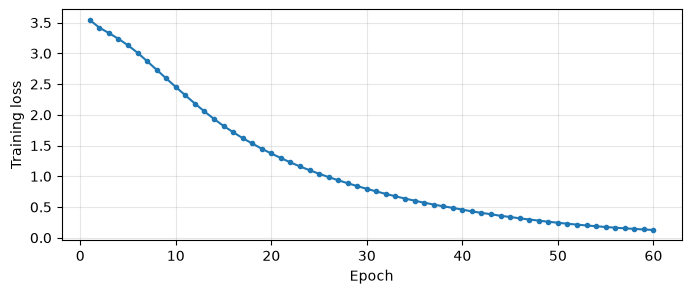

In [ ]:
# 이 코드는 눈에 들어와야 함.. keras cnn~ 쭉 했던 코드..
import time
LEARNING_RATE = 0.01   # 한 번에 가중치를 고치는 크기
EPOCHS = 60          # 동작만 확인할 때는 2

# 이 셀은 실행할 때마다 학습 전 가중치로 되돌린 뒤 학습합니다. (설정을 바꿔 다시 실행해도 공정하게 비교)
model.set_weights(weights_before)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
              loss=masked_token_loss, metrics=[masked_token_accuracy])
# 세 입력과 정답을 함께 묶어 공급 (전체 3개를 한 배치로 → epoch마다 업데이트 1회)
train_ds = tf.data.Dataset.from_tensor_slices(((X,X_mask,decoder_in),decoder_target)).batch(B)

# [참고용: 강사님 말씀 — 아래 options 3줄은 없어도 된다] (학습 결과나 동작에 필요한 줄이 아님)
# tf.data.Options: '입력 데이터 공급(tf.data 파이프라인)'의 실행 방식을 정하는 설정 묶음입니다.
#   (학습 과정 설정이 아님 — 학습 설정은 compile(optimizer, loss)·fit(epochs, callbacks) 쪽입니다.)
options = tf.data.Options()
# 데이터 공급 작업이 쓸 '전용(private) 스레드 풀'의 크기 = 1개. 병렬로 늘리는 설정이 아니라 오히려 1개로 제한합니다.
#   (CPU 코어가 여러 개인 것은 맞지만, 이 줄은 '코어를 많이 쓴다'가 아니라 데이터 공급용 스레드를 1개로 정하는 것입니다.)
options.threading.private_threadpool_size = 1
# with_options는 옵션이 적용된 '새' 데이터셋을 돌려줍니다(원본은 그대로). 그래서 train_ds에 다시 대입합니다.
train_ds = train_ds.with_options(options)
# 자세한 설명은 바로 아래 md 셀 'Q. tf.data.Options …' 참고

start = time.time() # 현재 시스템 시간
history = model.fit(train_ds, epochs=EPOCHS, callbacks=[keras.callbacks.TerminateOnNaN()], verbose=0) # 학습 중에는 아무 것도 표시하지 않음
print(f"학습 시간: {time.time()-start:.1f}초")
# 10 epoch마다 기록 출력
for epoch in sorted(set(range(0, EPOCHS, 10)) | {EPOCHS-1}):
    print(f"epoch {epoch+1:3d}  loss {history.history['loss'][epoch]:.4f}  "
          f"accuracy {history.history['masked_token_accuracy'][epoch]:.4f}")
max_weight_change = max(float(np.max(np.abs(a-b))) for a,b in zip(weights_before,model.get_weights())) # 학습 전(weights_before) vs 학습 결과(model) 가중치
print("학습 전 대비 가중치 변화 최대:",max_weight_change)
assert max_weight_change > 0, "학습 설정을 확인하세요."
plt.figure(figsize=(8,3))
plt.plot(np.arange(1,len(history.history['loss'])+1),history.history['loss'],'o-',markersize=3)
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.grid(alpha=.3); plt.show()

### Q. 4-2의 "세 입력과 정답을 함께 묶어 공급 (전체 3개를 한 배치로 → epoch마다 업데이트 1회)" — 왜 3개이고, 묶는 설정은 코드 어디인가?

값과 동작은 이 노트북의 `X`·`decoder_in` 등과 같은 모양의 배열로 `tf.data`를 직접 만들어 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 먼저: 이 주석에는 "3"이 두 번 나오는데 서로 다른 3입니다
| 주석 속 말 | 3이 가리키는 것 | 값 |
|---|---|---|
| **"세 입력"** | 모델 **입력의 종류**가 3가지 | 음성 특징 `X`, 음성 마스크 `X_mask`, Decoder 입력 `decoder_in` (3-2에서 `keras.Model([audio_input, audio_mask_input, token_input], …)`로 정한 3개) |
| **"전체 3개를 한 배치로"** | **자료(문장·음성)의 개수** B | 5강에서 고른 음성 3개 (`B = 3`, 1-4의 `B, T, M = X_raw.shape`) |
- 즉 "입력 3가지 × 자료 3개"입니다. 둘이 우연히 같은 숫자 3이라 헷갈리기 쉽습니다.

#### 2. "세 입력과 정답을 묶는다"는 설정은 이 줄입니다
```python
train_ds = tf.data.Dataset.from_tensor_slices(((X, X_mask, decoder_in), decoder_target)).batch(B)
```
- **`((X, X_mask, decoder_in), decoder_target)`** 가 바로 "세 입력과 정답을 묶은" 부분입니다. 괄호 구조를 풀면:
```text
(  ( X ,  X_mask ,  decoder_in ) ,   decoder_target  )
   └────── 입력 3가지 ──────┘        └─ 정답(목표) ─┘
   → (입력들, 정답) 형태의 쌍
```
  - 안쪽 괄호 `(X, X_mask, decoder_in)` = **모델의 입력 3개**(모델을 만들 때 적은 순서 `audio`, `audio_mask`, `decoder_tokens`와 같은 순서).
  - 바깥 `( 입력들 , decoder_target )` = **(입력, 정답)** 한 쌍. Keras `fit`은 데이터셋의 원소를 이 모양(입력, 정답)으로 받아서 "입력으로 예측 → 정답과 비교해 손실"을 계산합니다 **(일반 지식)**.
- 그래서 `fit`을 부를 때 `model.fit(train_ds, …)`처럼 **데이터셋 하나만** 넘기고, `X`, `y`를 따로 넘기지 않습니다.

#### 3. `from_tensor_slices`는 무엇을 하나 (직접 확인)
- 배열 묶음을 **첫 번째 축(자료 축)을 따라 한 자료씩 잘라** 데이터셋의 원소로 만듭니다. 여기서는 자료 3개이므로 원소가 **3개**입니다.
- 원소 하나(= 문장 하나)의 모양: `((음성 (1290, 40), 마스크 (1290,), Decoder 입력 (18,)), 정답 (18,))` — 앞에 붙어 있던 자료 축 3이 사라진 모양입니다.

#### 4. `.batch(B)`는 무엇을 하나 → "전체 3개를 한 배치로"
- `.batch(n)`은 원소를 **n개씩 묶어** 다시 쌓습니다. `B = 3`이므로 **3개를 전부 한 묶음**으로 만듭니다. 직접 확인:

| 설정 | 묶음(배치) 수 | 한 묶음 안의 자료 수 |
|---|---|---|
| `.batch(3)` (이 코드) | **1개** | 3개 (한 묶음의 모양 `(3, 1290, 40)`, `(3, 1290)`, `(3, 18)` / 정답 `(3, 18)`) |
| `.batch(2)` | 2개 | 2개, 1개 |
| `.batch(1)` | 3개 | 1개씩 |
- 학습에서는 **배치 하나를 처리할 때마다 가중치를 한 번 업데이트**합니다 **(일반 지식)**. 배치가 **1개**이므로 **epoch 한 번에 업데이트가 1번**입니다. 주석의 "→ epoch마다 업데이트 1회"가 이 뜻입니다. `.batch(1)`로 바꾸면 epoch마다 3번 업데이트됩니다.
- `EPOCHS = 60`이면 총 **60번** 업데이트됩니다. 가진 자료가 3개뿐이라 "전체를 한 번에" 쓰는 단순한 구조입니다.

#### 5. 이 코드와 3-2 모델의 연결
- 3-2에서 모델 입력을 `[audio_input, audio_mask_input, token_input]` 순서로 정했습니다. 데이터셋의 입력 튜플 `(X, X_mask, decoder_in)`이 **같은 순서**여야 각 입력이 알맞은 층으로 들어갑니다. 3-3에서 `model([X, X_mask, decoder_in])`로 순전파를 한 것도 같은 순서입니다.
- 정답 `decoder_target`은 모델 출력 `(3, 18, 35)`와 비교됩니다(위치마다 정답 번호 `(3, 18)`, 4-1의 `masked_token_loss`).

### Q. `tf.data.Options()`와 `options.threading.private_threadpool_size = 1`은 무엇인가? (4-2의 options 3줄)

값과 설명은 이 환경(TensorFlow 2.16.2)에 설치된 TensorFlow 소스의 설명문과 직접 실행으로 확인했습니다. 강사님이 수업에서 이 줄을 왜 넣었다고 설명하셨는지는 듣지 못해 **확인하지 못했고**, 추측한 부분은 **추정**으로 표시했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다.

#### 1. 내가 적었던 주석 점검
| 원래 주석 | 점검 | 고친 내용 |
|---|---|---|
| `# 학습 과정 관리하는 options?` | **부정확합니다.** 이 `options`는 학습 과정(손실·최적화·epoch)이 아니라 **입력 데이터를 공급하는 방식(`tf.data` 파이프라인)** 에 대한 설정입니다. 학습 과정 설정은 `compile(optimizer, loss)`와 `fit(epochs, callbacks)`입니다. | "입력 데이터 공급(tf.data)의 실행 방식을 정하는 설정 묶음" |
| `# 오늘날 컴퓨터는 멀티프로세싱` | **절반만 맞고, 이 줄의 의미와는 반대입니다.** 요즘 컴퓨터가 코어 여러 개라는 것은 맞지만(이 컴퓨터는 `os.cpu_count()`가 4), **이 줄은 병렬을 늘리는 것이 아니라 데이터 공급용 스레드를 1개로 제한**합니다. 또 용어도 **프로세스(process)가 아니라 스레드(thread)** 입니다 **(일반 지식: 프로세스는 별도의 실행 프로그램 단위, 스레드는 한 프로그램 안의 실행 흐름)**. | "데이터 공급 전용 스레드 수 = 1개(병렬로 늘리는 설정이 아님)" |
- 코드 셀의 해당 주석 두 줄을 위 내용으로 고쳐 두었습니다(코드는 그대로이고 주석만 바꿈).

#### 2. 세 줄을 풀어 읽기
```python
options = tf.data.Options()                          # ① 설정을 담을 빈 '옵션 상자'를 만듦
options.threading.private_threadpool_size = 1        # ② 그 상자의 threading(스레드) 항목을 1로 설정
train_ds = train_ds.with_options(options)            # ③ 데이터셋에 이 옵션을 적용한 '새' 데이터셋을 받음
```
- **① `tf.data.Options()`**: `tf.data`(데이터 공급 도구)의 **옵션 묶음**입니다. 만든 직후에는 **아무것도 정해지지 않은 상태**입니다(직접 확인: `private_threadpool_size`가 `None`).
- **② `options.threading.private_threadpool_size = 1`**: `threading`은 옵션 묶음 안의 **스레드 관련 설정 칸**이고, 그 안의 `private_threadpool_size`가 이 줄의 대상입니다. TensorFlow 설명문(소스에서 확인): *"If set, the dataset will use a private threadpool of the given size. The value 0 can be used to indicate that the threadpool size should be determined at runtime based on the number of available CPU cores."* → **"설정하면 데이터셋은 주어진 크기의 전용(private) 스레드 풀을 쓴다. `0`이면 사용 가능한 CPU 코어 수에 따라 실행 시 크기를 정한다."** 즉 `= 1`은 **데이터 공급 작업을 스레드 1개로 하라**는 뜻입니다(스레드 풀: 일을 나눠 맡는 일꾼 스레드들의 묶음 **(일반 지식)**).
- **③ `with_options`**: 옵션이 적용된 **새로운 데이터셋**을 돌려줍니다(직접 확인: 새 객체이고 원본은 `None` 그대로, 새 것은 `1`). 그래서 `train_ds.with_options(options)`만 쓰면 효과가 없고 `train_ds = …`로 **다시 대입**해야 합니다.

#### 3. 이 줄이 하는 일과 안 하는 일
- **하는 일**: `fit`이 데이터셋에서 배치를 꺼낼 때 데이터 공급 쪽이 쓸 **스레드 수를 1개로** 정합니다.
- **안 하는 일**: 모델의 계산(LSTM 등), 손실, 가중치 업데이트 방식은 **바꾸지 않습니다**(그것은 `compile`·`fit`과 모델 쪽).
- 이 노트북의 데이터 공급은 `from_tensor_slices(...).batch(B)`뿐(자료 3개를 잘라 한 묶음으로 쌓음)이라 **병렬로 처리할 일이 거의 없습니다(추정)**.
- **직접 확인한 것**: 같은 구조의 작은 LSTM 예제(자료 3개, 같은 시드)에서 **옵션을 쓴 경우와 안 쓴 경우의 5 epoch 손실이 완전히 같았습니다**(`1.093682, 1.03998, 0.987586, 0.935907, 0.884482`). 이 노트북의 모델로 직접 비교한 것은 아니지만, 이 줄을 지워도 같은 방식으로 학습이 돌아갈 것으로 보입니다(추정).

#### 4. 이 줄들의 위치: 참고용 (없어도 됨)
- **강사님이 수업에서 "이 3줄은 없어도 된다"고, 참고용으로 보여 주신 것**이라고 합니다(학생이 전해 준 내용이며, 저는 수업을 듣지 못해 직접 확인하지 못했습니다).
- 위 3번의 확인과 맞아떨어집니다. 데이터 공급이 `from_tensor_slices(...).batch(B)`뿐이고, 같은 구조의 작은 예제에서 **옵션이 있든 없든 학습 손실이 같았기 때문**입니다.
- 그러므로 **`train_ds = …batch(B)`까지만 있어도 `fit`은 동작**합니다. 이 줄들은 "`tf.data`에는 이런 옵션도 있다"는 **참고용 예**로 보면 됩니다. 필요해지는 경우는 데이터가 많아 `map`·`shuffle` 같은 가공이 무거워지고, 스레드 수를 조절하고 싶을 때입니다 **(일반 지식)**.
- (처음에 제가 적었던 "왜 넣었을지" 추측은 참고용이라는 설명으로 정리하며 지웠습니다.)


### 관찰·직접 적용 · 4-2

첫 손실과 마지막 손실, 가중치 변화량을 기록하세요. 그다음 `LEARNING_RATE = 0.001`, `EPOCHS = 20`으로 바꿔 4-2부터 4-5까지 다시 실행하고 결과가 어떻게 달라지는지 비교하세요. 비교가 끝나면 기본값으로 되돌려 다시 실행합니다.

셀 첫 부분의 `model.set_weights(weights_before)`가 없다면 셀을 다시 실행할 때 어떤 일이 생길지도 설명하세요.

**완료 기준:** 가중치 변화가 0보다 커지고 마지막 손실이 첫 손실보다 작습니다. 손실·정답률의 정확한 숫자는 환경에 따라 조금 다를 수 있습니다.

### 내 기록 · 4-2

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-2 — 먼저 자신의 기록을 작성하세요</summary>

`fit()`은 현재 가중치에서 이어서 학습합니다. 이 셀은 `set_weights(weights_before)`로 출발점을 되돌리고 `compile()`로 optimizer를 새로 만들기 때문에 설정끼리 공정하게 비교할 수 있습니다. 되돌리지 않으면 다시 실행할 때마다 학습이 누적되어 "설정을 바꿨더니 좋아졌다"는 결론이 틀릴 수 있습니다.

전체 자료가 한 배치이므로 epoch마다 업데이트는 한 번입니다. 학습률 0.001·20 epoch에서는 업데이트가 20번뿐이라 손실이 조금만 줄고, 세 음성 모두 같은 문장을 내는 상태에 머뭅니다.

</details>

<a id="practice-4-3"></a>
## 실습 4-3 · 학습 후 교사 강요 예측 비교 [기본 실습]

**이론 연결:** [HTML 4-3 · 학습 후 교사 강요 예측 비교](lesson06_theory.html#practice-4-3)

**실행 목적:** 학습 전후 손실과 후보가 달라질 수 있습니다. 전체 정답 일치는 완료 조건이 아닙니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [31]:
after_probs = model(train_inputs,training=False).numpy()   # 학습 후 예측(keras model.predict()) (교사 강요)
scores = {}
for name, probs in [('before',before_probs),('after',after_probs)]:
    loss = float(masked_token_loss(decoder_target,probs).numpy().mean())
    acc = float(masked_token_accuracy(decoder_target,probs).numpy().mean())
    scores[name] = dict(loss=loss, accuracy=acc)
    print(name, "문장 평균 loss:",round(loss,4),"문장 평균 token accuracy:",round(acc,4))
# fit 로그의 마지막 loss는 마지막 업데이트 '직전' 값이라 위 after와 조금 다릅니다.
print("fit 마지막 epoch 로그 loss:", round(history.history['loss'][-1],4))
chosen_after = after_probs.argmax(axis=-1)
for i in range(B):
    target_tokens = [inverse[int(t)] for t in decoder_target[i,target_mask[i]]]
    predicted_tokens = [inverse[int(t)] for t in chosen_after[i,target_mask[i]]]
    print(ids[i], "목표:",target_tokens)
    print("교사 강요 입력의 예측:",predicted_tokens)

before 문장 평균 loss: 3.5429 문장 평균 token accuracy: 0.037
after 문장 평균 loss: 0.1188 문장 평균 token accuracy: 1.0
fit 마지막 epoch 로그 loss: 0.1265
1272-128104-0001 목표: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>']
교사 강요 입력의 예측: ['안녕하세요.', '오늘은', '음성', '데이터를', '함께', '살펴봅니다', '<eos>']
1272-128104-0006 목표: ['수업이', '끝나면', '친구와', '도서관에', '가서', '오늘', '배운', '내용을', '정리하려고', '합니다', '<eos>']
교사 강요 입력의 예측: ['수업이', '끝나면', '친구와', '도서관에', '가서', '오늘', '배운', '내용을', '정리하려고', '합니다', '<eos>']
1272-128104-0008 목표: ['길이가', '다른', '음성', '파일을', '하나로', '묶으려면', '짧은', '자료의', '뒤에', '값을', '채우고', '실제', '데이터가', '있는', '구간을', '표시해야', '합니다', '<eos>']
교사 강요 입력의 예측: ['길이가', '다른', '음성', '파일을', '하나로', '묶으려면', '짧은', '자료의', '뒤에', '값을', '채우고', '실제', '데이터가', '있는', '구간을', '표시해야', '합니다', '<eos>']


위 output 해석 = 학습한 건 잘 예측한다?

### 관찰·직접 적용 · 4-3

이전 정답 토큰을 주는 변수를 찾으세요. 이 결과를 음성만으로 얻은 인식 결과라고 할 수 없는 이유를 적으세요.

**완료 기준:** 학습 전후 손실과 후보가 달라질 수 있습니다. 전체 정답 일치는 완료 조건이 아닙니다.

### 내 기록 · 4-3

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-3 — 먼저 자신의 기록을 작성하세요</summary>

train_inputs의 세 번째 decoder_in이 이전 정답입니다. 자유 생성에서는 모델 자신의 직전 예측을 사용합니다.

</details>

<a id="practice-4-4"></a>
## 실습 4-4 · 공유 레이어로 추론 모델 구성 [기본 실습]

교사 강요 사용하지 않고, en/decoder에 데이터 넣은 모델? -> 첫번째 어절 예측

**이론 연결:** [HTML 4-4 · 공유 레이어로 추론 모델 구성](lesson06_theory.html#practice-4-4)

**실행 목적:** 한 단계 모델의 확률이 학습 모델 첫 위치의 확률과 일치합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [32]:
# 한 단계 Decoder: (직전 토큰, h, c) → (다음 확률, 새 h, 새 c)
# [이 셀의 흐름: 크게 3묶음]
#   ① 한 단계용 입력 3개를 정의  →  ② 3-2에서 만든 같은 레이어로 연결  →  ③ Model로 조립하고 학습 모델과 같은지 검증
# [왜 만드나] 학습(4-2)은 정답을 한 번에 통째로 넣는 교사 강요였습니다. 추론에는 정답이 없으므로
#   "직전에 나온 토큰 하나 + 지금까지의 기억(h, c)"만 넣어 "다음 토큰 확률"을 구하는 한 단계 모델이 필요합니다.
#   이것을 반복하는 것이 4-5의 generate_tokens()입니다.

# ───── ① 한 단계용 입력 3개 (모양에 '시간 길이' 자리가 없음 = 한 번에 토큰 1개) ─────
step_token = keras.Input(shape=(1,),dtype='int32',name='step_token') # 배치당 토큰 1개: 직전에 나온 토큰의 번호 (첫 단계는 BOS), 모양 (배치, 1)
step_h = keras.Input(shape=(UNITS,),name='step_h') # hidden state(h): LSTM의 '지금까지의 요약' 벡터, 실수 32개 (※ unsigned integer가 아님), 모양 (배치, 32)
step_c = keras.Input(shape=(UNITS,),name='step_c') # cell state(c): LSTM의 '장기 기억' 벡터, 실수 32개, 모양 (배치, 32)

# ───── ② 3-2에서 만든 '같은 레이어 객체'를 호출 (새로 만들지 않음 → 학습된 가중치를 그대로 사용) ─────
# 새 레이어 대신 3-2에서 만든 같은 객체를 호출합니다.
step_embedded = embedding_layer(step_token)                                  # 번호 → 24차원 벡터
step_states, next_h, next_c = decoder_lstm(step_embedded,initial_state=[step_h,step_c])  # 입력 h, c에서 시작해 한 칸 진행 → 출력, 새 h, 새 c
step_probs = output_layer(step_states) # 다음 토큰 후보 35개의 확률 (예측하는 값), 모양 (배치, 1, 35)

# ───── ③ Model로 조립: 입력 3개 [토큰, h, c] → 출력 3개 [확률, 새 h, 새 c] ─────
#   새 h, c도 출력하는 이유: 다음 단계의 입력 h, c로 이어 쓰기 위해서(상태를 전달하며 한 토큰씩 생성)
decoder_step_model = keras.Model([step_token,step_h,step_c],[step_probs,next_h,next_c],name='decoder_step')

# ───── ③' 검증: 같은 음성 + BOS를 넣으면 학습 모델의 '첫 위치' 확률과 같아야 함 ─────
# 같은 음성 + BOS → 학습 모델 첫 위치와 같은 확률이어야 함
h, c = encoder_model([X[:1],X_mask[:1]],training=False) # encoder 모델이 음성 하나를 읽어 만든 초기 상태 h, c (Decoder의 출발점)
p, _, _ = decoder_step_model([tf.constant([[BOS]],dtype=tf.int32),h,c],training=False) # BOS 하나를 넣은 한 단계 결과 (새 h, c는 여기서 안 써서 _로 버림)
np.testing.assert_allclose(p.numpy()[0,0],after_probs[0,0],atol=1e-5,rtol=1e-5) # 학습 후 전체 모델의 첫 위치 확률(after_probs[0,0])과 거의 같은지 확인
print("한 단계 출력:",p.shape,"첫 위치의 일치 확인")

한 단계 출력: (1, 1, 35) 첫 위치의 일치 확인


### Q. 실습 4-4의 흐름 — 코드 3묶음은 서로 어떤 관계인가? (공유 레이어 추론 모델)

동작은 이 노트북의 3-2 모델과 같은 구조·크기(UNITS 32, Embedding 24, V 35, Mel 40)의 작은 예제를 이 환경에서 직접 만들어 확인했습니다. 일반 상식은 **(일반 지식)**으로 표시했습니다. 강사님이 "3묶음"을 정확히 어떻게 나누셨는지는 듣지 못해 확인하지 못했고, 아래 묶음은 **코드의 구분선(주석)을 기준으로 제가 나눈 것**입니다.

#### 1. 목적: 학습 모델과 추론 모델은 입력 방식이 다릅니다
| | 학습(3-2, 4-2) — 교사 강요 | 추론(4-4, 4-5) — 정답 없이 |
|---|---|---|
| Decoder에 넣는 것 | **정답 전체** `[BOS, 안녕하세요., 오늘은, …]`를 **한 번에** | **직전에 나온 토큰 하나**와 상태 `h, c` |
| 출력 | 모든 위치의 확률 `(B, U, V)`를 한 번에 | **다음 한 토큰**의 확률 `(배치, 1, 35)`와 새 `h, c` |
| 사용할 때 | 정답을 알고 있으므로 가능 | 정답이 없으므로 **한 단계씩 반복** |
- 그래서 **같은 가중치를 쓰되 "한 칸씩 진행하는 모양"의 모델**이 필요하고, 그것이 `decoder_step_model`입니다. 이 셀은 모델을 **만들고, 학습 모델과 같은지 확인**하는 단계이고 실제 생성은 4-5(`generate_tokens`)에서 합니다.

#### 2. 코드 3묶음과 서로의 관계
```text
① 입력 정의                 ② 레이어 연결(3-2의 같은 레이어)            ③ 조립 + 검증
step_token (배치,1)  ───▶ embedding_layer ─▶ decoder_lstm ─▶ output_layer ───▶ Model(입력3 → 출력3)
step_h     (배치,32) ───▶  (initial_state = [step_h, step_c]) ─┘                 └ 검증: encoder의 h,c + BOS
step_c     (배치,32) ───┘                                                          → 학습 모델 첫 위치 확률과 일치
```
- **① 입력 3개**: Decoder를 한 칸 돌리려면 필요한 재료 3가지(직전 토큰, `h`, `c`)를 **빈 입력 자리**로 정의합니다. 학습 모델에서는 `[state_h, state_c]`가 Encoder에서 자동으로 왔지만, 여기서는 **밖에서 넣어 주는 자리**로 만듭니다.
- **② 레이어 연결**: 3-2에서 만든 **같은 레이어 객체**(`embedding_layer`, `decoder_lstm`, `output_layer`)를 ①의 입력에 다시 연결합니다. 이것이 "공유 레이어"입니다. 직접 확인: 두 모델이 **같은 레이어 객체를 가리킵니다**(가중치 동일 객체 `True`).
- **③ 조립과 검증**: ②를 `keras.Model([입력 3], [확률, 새 h, 새 c])`로 묶고, **같은 음성 + BOS**로 한 단계 돌려 **학습 모델 첫 위치의 확률(`after_probs[0,0]`)과 같은지**(`assert_allclose`) 확인합니다.
- **①→②→③의 연결**: ①은 재료, ②는 "학습된 가중치로 계산하는 경로", ③은 "그 경로가 학습 모델과 실제로 같은 결과를 내는지의 증명"입니다.

#### 3. 왜 레이어를 "새로 만들지 않고 공유"하나 (이 실습의 핵심)
- 새 `LSTM`·`Dense`를 만들면 **가중치가 새로 무작위로 초기화**되어 학습한 내용이 없습니다. 직접 확인: 같은 구조에서 `Dense`만 새로 만들어 연결하면 **첫 위치 확률이 학습 모델과 일치하지 않았습니다(`False`)**, 같은 레이어를 쓰면 일치했습니다(`True`).
- 공유한 Model은 **가중치를 복사하는 것이 아니라 같은 객체를 쓰므로** 학습(4-2)으로 가중치가 바뀌면 `decoder_step_model`도 **자동으로 같이 바뀐 가중치**를 씁니다(공개 해설: "별도 Model을 구성하는 것은 가중치를 새로 초기화하는 것과 다릅니다"). 그래서 4-4의 관찰 질문 답은 **재사용한 레이어 변수 세 개 = `embedding_layer`, `decoder_lstm`, `output_layer`** 입니다.

#### 4. 출력 읽기
```text
한 단계 출력: (1, 1, 35) 첫 위치의 일치 확인
```
- `(1, 1, 35)` = 음성 1개 × 위치 1개(토큰 하나만 넣었으므로) × 후보 35개의 확률.
- **일치 확인**이 통과했다는 것은 "BOS 하나를 넣은 한 단계 모델"이 "학습 모델이 첫 위치에서 계산한 확률"과 같다는 뜻입니다. 직접 확인한 작은 예제에서는 **둘째 위치도**(`h, c`를 이어 받아 다음 토큰 `2`를 넣으면) 학습 모델의 둘째 위치 확률과 일치했습니다 → 상태를 이어 가며 한 토큰씩 진행해도 전체를 한 번에 넣은 것과 같은 결과가 됩니다.

#### 5. 이 셀 제목 아래 적어 둔 내 메모 점검
> "교사 강요 사용하지 않고, en/decoder에 데이터 넣은 모델?"
- **방향은 맞습니다.** 이 모델은 정답을 통째로 넣는 교사 강요가 아니라, **직전 토큰 하나와 상태만** 받는 구조입니다. 다만 정확히는 이 셀에서 **Encoder와 Decoder에 데이터를 "넣은 모델"을 만드는 것**이 아니라, ① Encoder 모델(3-1)은 그대로 두고 음성에서 `h, c`를 얻는 데 쓰고, ② **Decoder 부분만 한 단계 모델로 새로 구성**합니다. 실제로 반복해서 생성하는 것은 다음 4-5입니다.
- 코드 속 `step_h`의 주석 "unsigned integer"는 **틀렸습니다**(수정함): `h`는 정수가 아니라 **실수 벡터**(`float32`, 모양 `(배치, 32)`)입니다(직접 확인: `dtype float32`). `step_token`만 정수(`int32`)입니다.

### 관찰·직접 적용 · 4-4

재사용한 레이어 변수 세 개를 찾고 새로 만들면 안 되는 이유를 설명하세요.

**완료 기준:** 한 단계 모델의 확률이 학습 모델 첫 위치의 확률과 일치합니다.

### 내 기록 · 4-4

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-4 — 먼저 자신의 기록을 작성하세요</summary>

embedding_layer·decoder_lstm·output_layer를 공유합니다. 별도 Model을 구성하는 것은 가중치를 새로 초기화하는 것과 다릅니다.

</details>

<a id="practice-4-5"></a>
## 실습 4-5 · 음성만으로 자유 생성하고 비교 [기본 실습]

**이론 연결:** [HTML 4-5 · 음성만으로 자유 생성하고 비교](lesson06_theory.html#practice-4-5)

**실행 목적:** 정답 없이 음성만으로 문장을 생성합니다(예측 결과 나옴). 기본 설정에서는 학습한 세 문장을 그대로 생성하는 경우가 많지만, 학습 자료이므로 시험 성능이 아닙니다. 오인식·반복·빈 문장·상한 종료도 모두 가능한 결과이며 실제 출력 그대로 기록합니다.

**진행:** 앞선 기본 셀을 실행한 후 아래 코드를 실행합니다. 다음 관찰 항목을 확인하고 자신의 기록을 작성하세요.

In [33]:
def generate_tokens(audio_batch, mask_batch, max_tokens=40): # 토큰 개수에 의해? 무한 반복에 빠지지 않도록 값 제한해둠
    # 음성만 보고 한 토큰씩 생성 (매 단계 최고 확률 선택)
    assert len(audio_batch) == 1, "한 번에 음성 하나씩 생성합니다."
    h, c = encoder_model([audio_batch,mask_batch],training=False)   # 음성 → 상태
    current = tf.constant([[BOS]],dtype=tf.int32)                   # 첫 입력은 BOS
    result, trace = [], [] # 생성한 id와 진행되는 상태 각각 저장
    reason = '최대 토큰 수' # 마지막에 EOS가 나오지 않는 경우, 모델이 예측한 문장이 EOS로 끝나지 않는 경우
    for step in range(max_tokens):
        probs, h, c = decoder_step_model([current,h,c],training=False) # 학습하지 않고, 해당 모델의 예측 결과를 냄
        original = probs.numpy()[0,0] # 후보 확률
        selectable = original.copy()
        selectable[[PAD,BOS]] = -np.inf          # PAD·BOS는 무한대로 둠 -> 후보에서 제외
        token = int(selectable.argmax())
        trace.append((step,inverse[int(current[0,0])],inverse[token],float(original[token]))) # 단계, 입력, 출력, 확률
        if token == EOS:
            reason = 'EOS'
            break
        result.append(token) # token이 EOS가 아니면 실행되는 line
        current = tf.constant([[token]],dtype=tf.int32)   # 방금 고른 토큰이 다음 입력
    return result, trace, reason

free_results = []
for i in range(B): # B = 3, 3개의 문장
    result, trace, reason = generate_tokens(X[i:i+1],X_mask[i:i+1]) # 0,1,2
    text = ' '.join(inverse[t] for t in result) # 패딩이 뒤에 있으니까 거꾸로 처리, id -> 어절, 예측된 문장
    reference_normalized = ' '.join(tokenize(references[i])) # 정답
    free_results.append(dict(id=ids[i],prediction=text,reference=reference_normalized,stop=reason,trace=trace))
    print(ids[i],"정답:",reference_normalized)
    print("자유 생성:",repr(text),"종료:",reason,"일치:",text==reference_normalized)
print("첫 음성의 생성 과정 앞 5단계:")
for step in free_results[0]['trace'][:5]:
    print(step)

1272-128104-0001 정답: 안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다
자유 생성: '안녕하세요. 오늘은 음성 데이터를 함께 살펴봅니다' 종료: EOS 일치: True
1272-128104-0006 정답: 수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다
자유 생성: '수업이 끝나면 친구와 도서관에 가서 오늘 배운 내용을 정리하려고 합니다' 종료: EOS 일치: True
1272-128104-0008 정답: 길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다
자유 생성: '길이가 다른 음성 파일을 하나로 묶으려면 짧은 자료의 뒤에 값을 채우고 실제 데이터가 있는 구간을 표시해야 합니다' 종료: EOS 일치: True
첫 음성의 생성 과정 앞 5단계:
(0, '<bos>', '안녕하세요.', 0.9443098902702332)
(1, '안녕하세요.', '오늘은', 0.9199381470680237)
(2, '오늘은', '음성', 0.9204337000846863)
(3, '음성', '데이터를', 0.9171746969223022)
(4, '데이터를', '함께', 0.9274324774742126)


### 질문·답변 정리 — 4-1에서 `keras.utils`에 등록한 함수 vs 4-5의 `generate_tokens()`, 어떨 때 등록하나?

**강사님께 드린 질문:**
> 오늘 실습 4-1에서 keras.utils에 등록한 함수와 조금 전에 막 살펴본 실습 4-5의 generate_tokens() 함수의 차이로써, 어떨 때 keras.utils에 등록하여 사용하는지 정확히 이해를 못했습니다.

**강사님 답변 — 내가 메모/이해한 것:**
- 실습 4-1 = keras에 있는 기능인 accuracy와 loss를 사용할 수 없기 때문에 내가 keras.utils에 등록함 → keras 기능을 .. 모델 불러올 때/로드해서 쓸모 있는 Keras 기능 함수
- 실습 4-5 = 예측/문장 생성하는 파이썬 함수

**아래는 이 정리에 대한 제 생각과 메모 피드백입니다.** 동작은 이 환경(TensorFlow 2.16 / Keras 3)에서 **작은 별도 모델로 직접 실행해 확인**했습니다(이 노트북의 모델로 한 것은 아님). 일반 상식은 **(일반 지식)**으로 표시했습니다. 강사님의 실제 설명 전체는 듣지 못해, **학생 메모를 기준으로** 정리했습니다.

#### 1. 한 줄 답
- **`@keras.utils.register_keras_serializable(...)`는 "이 함수의 이름을 Keras가 기억해 두라"는 등록**이고, **모델을 저장했다가 다시 불러올 때(`load_model`) Keras가 그 이름으로 함수를 찾아내게 하려는 것**입니다.
- 4-1의 두 함수(`masked_token_loss`, `masked_token_accuracy`)는 **모델의 `compile` 설정 속에 들어가는 "Keras 부품"** 이라 등록 대상이고, 4-5의 `generate_tokens()`는 **모델 바깥에서 우리가 직접 호출하는 일반 파이썬 함수**라 등록할 이유가 없습니다.

#### 2. 질문에 숨은 두 가지를 나누면 이해가 쉽습니다
| | 질문 | 4-1의 답 |
|---|---|---|
| **A. 왜 직접 만들었나?** | 내장 loss·accuracy를 그냥 쓰면 안 되나? | **PAD 위치까지 계산에 들어가므로** 이 문제에는 맞지 않아서, **PAD를 뺀** 손실·정확도를 직접 만들었습니다(4-1, 앞의 "PAD를 제외한 손실" 설명 셀) |
| **B. 왜 등록(`@register…`)했나?** | 직접 만들었으면 바로 쓰면 되지 않나? | **저장한 모델을 다시 불러올 때** Keras가 함수를 찾을 수 있게 하려고 |
- **A와 B는 별개입니다.** 직접 만든 함수는 **등록하지 않아도** `compile(loss=…)`에 넣어 `fit`하는 데 문제가 없습니다(아래 실험). **등록은 "저장·불러오기" 단계에서만 효과가 있습니다.**

#### 3. 직접 확인한 실험 (작은 모델, 직접 만든 손실 함수)
| 상황 | 결과 |
|---|---|
| 등록 **안 한** 손실 함수를 `compile`에 넣고 `fit`, `model.save` | **둘 다 성공** (등록은 학습·저장에 필요 없음) |
| 그 모델을 **새 프로세스에서 `load_model`** — 함수 정의를 불러온 뒤에도 | **실패**: `TypeError: Could not locate function 'masked_loss'. Make sure custom classes and functions are decorated with @keras.saving.register_keras_serializable()` |
| 같은 경우에 `load_model(…, custom_objects={'masked_loss': 함수})`로 **직접 알려 주면** | 성공 |
| **등록한** 손실 함수로 저장 → 새 프로세스에서 **정의(등록)만 불러오면** | 성공 (`custom_objects` 없이) |
| 등록한 모델을 새 프로세스에서 **함수 정의 없이** 불러오면 | 실패: `Could not locate function 'SpeechLesson>masked_loss'` (등록 이름이 **`패키지>함수이름`** 형태로 파일에 기록됨) |
- 풀어 말하면: 저장된 모델 파일에는 함수의 **코드가 아니라 이름**이 적혀 있습니다. 불러올 때 Keras가 그 이름을 **등록부**에서 찾는데, **등록해 두었으면 자동으로 찾고**, 등록 안 했으면 `custom_objects`로 직접 알려 줘야 합니다 **(일반 지식과 위 실험)**.
- `package='SpeechLesson'`은 이름 앞에 붙는 **소속 이름**(다른 곳의 같은 이름 함수와 겹치지 않게)입니다.

#### 4. 그럼 언제 등록하나 (기준)
- **모델의 설정(config)에 "이름"으로 기록되는 사용자 정의 객체**(손실, 지표, 층, 활성화 함수, 초기화·규제 함수 등)를 만들었고, **저장한 모델을 다른 곳(새 노트북, 다른 사람, 나중의 나)에서 `load_model`로 열어 쓸 때** 등록해 둡니다 **(일반 지식)**.
- 등록하지 않고 쓰는 방법: `load_model(..., custom_objects={...})` 또는 `with keras.utils.custom_object_scope({...}):`로 불러올 때 알려 주기.
- **등록이 필요 없는 것**: 모델 안에 들어가지 않는 일반 함수. 데이터 준비, 결과 출력, **문장 생성 루프**(`generate_tokens`) 등.

#### 5. 4-1 vs 4-5 비교
| | 4-1 `masked_token_loss`, `masked_token_accuracy` | 4-5 `generate_tokens()` |
|---|---|---|
| 누가 부르나 | **Keras가** 학습 중 `compile`에서 호출 | **내가** 직접 호출 |
| 하는 일 | 모델 출력과 정답을 비교해 손실·정확도 계산(PAD 제외) | 음성만 보고 한 토큰씩 생성 |
| 입력·출력 | `(y_true, y_pred)` 텐서 → 값 | 음성 배치 → 토큰 리스트·진행 기록·종료 이유 |
| 모델 저장 파일에 이름이 남나 | **남음**(`compile` 설정) | **안 남음**(모델 구성요소가 아님) |
| 등록 필요? | **저장·로드할 거면 필요(편리)** | **필요 없음** |
| 코드 성격 | TensorFlow 연산(`tf.cast`, `tf.reduce_sum` …)으로 작성 | 파이썬 반복문·`if token == EOS: break`·`.numpy()` 사용 |
- 마지막 줄이 한 가지 단서입니다 **(일반 지식)**: Keras가 학습 중 호출하는 손실·지표는 **텐서 연산으로 작성**되어야 하고(4-1 코드가 전부 `tf.` 연산), `generate_tokens`처럼 값에 따라 반복을 중단하는 **일반 파이썬 제어문**은 Keras 학습 안에 넣는 함수가 아닙니다. 그래서 `generate_tokens`는 모델 파일에 포함되지 않고, **노트북/파이썬 코드로 따로 보관**해야 합니다(생성 방법은 모델 파일에 저장되지 않음).
- 참고: 이 노트북에는 `model.save` / `load_model` 호출이 **없습니다**(검색 확인). 즉 지금 실습에서 등록은 **없어도 학습·생성이 동작**하고, 나중에 모델을 저장해 다른 곳에서 쓸 때를 위한 습관에 가깝습니다(제 해석).

#### 6. 내 메모 피드백
| 메모 | 점검 |
|---|---|
| "keras에 있는 accuracy와 loss를 사용할 수 없기 때문에 내가 만듦" | **방향은 맞고 정확히는**: 사용할 수 *없는* 게 아니라, 내장 함수는 **PAD까지 계산에 넣어 이 문제에는 맞지 않아서** 직접 만든 것입니다(위 2번 A). |
| "…내가 keras.utils에 등록함" | **맞습니다.** 다만 **직접 만든 것(A)과 등록(B)은 별개 단계**입니다. 등록은 만든 뒤 한 번 더 하는 것입니다. |
| "모델 불러올 때/로드해서 쓸모 있는 Keras 기능 함수" | **정확합니다.** **저장한 모델을 다시 불러올 때** Keras가 이름으로 함수를 찾게 하는 용도입니다. |
| "실습4-5 = 예측/문장 생성하는 파이썬 함수" | **맞습니다.** 보충: 모델의 구성요소가 아니라 **모델 바깥에서 부르는 일반 함수**라서 저장 파일에 들어가지 않고 등록할 필요도 없습니다. |
| (4-1 코드의 내 주석) "keras의 utils에 기능 등/기록해둠 → **추후 새로운 데이터에 대해서도 사용 가능**" | **이 부분만 바로잡습니다.** 함수는 등록하지 않아도 **새 데이터에 그냥 쓸 수 있습니다**(그냥 함수니까). 등록의 효과는 "새 데이터"가 아니라 **"저장한 모델을 다시 불러올 때(다른 노트북·나중에)"** 입니다. 이 코드 주석은 제가 건드리지 않았으니 원하면 고쳐 드리겠습니다. |
- 추가: 4-5 코드의 `selectable[[PAD,BOS]] = -np.inf  # …무한대로 둠`은 "**음의 무한대(−∞)** 로 두어 `argmax`가 절대 고르지 못하게(후보에서 제외)"가 정확한 표현이고, `text = ' '.join(inverse[t] for t in result)  # 패딩이 뒤에 있으니까 거꾸로 처리`는 **패딩과 무관**합니다. `result`에는 패딩이 없고, 번호를 어절로 바꿔 공백으로 이어 붙이는 코드입니다(**"거꾸로 처리"는 `inverse`로 번호→어절 변환**을 가리키는 것으로 보입니다 — 추정).

### 관찰·직접 적용 · 4-5

생성 기록에서 전 단계 출력이 다음 입력이 되는지 확인하세요. 첫 단계에 EOS가 나오면 무엇이 표시되는지 설명하세요.

**완료 기준:** 오인식·반복·빈 문장·상한 종료가 모두 가능합니다. 실제 출력 그대로 기록합니다.

### 내 기록 · 4-5

- 확인한 값 또는 출력: **직접 작성**
- 이번 결과가 의미하는 것: **직접 작성**
- 관찰 질문에 대한 답: **직접 작성**

<details><summary>공개 해설 · 4-5 — 먼저 자신의 기록을 작성하세요</summary>

첫 출력이 EOS이면 빈 문자열입니다. 자유 생성에서는 잘못된 예측도 다음 입력에 들어갑니다.

</details>


## 최종 점검

- 같은 ID로 WAV·X·정답을 연결하고, 5강 저장값과 특징 재계산값의 일치를 확인했습니다.
- Encoder 입력 마스크와 정답 PAD 제외가 서로 다른 역할임을 설명할 수 있습니다.
- BOS·EOS와 한 칸 이동한 Decoder 입력·정답을 만들었습니다.
- Keras의 각 층과 입력·출력 모양을 설명할 수 있습니다.
- 실제 가중치 업데이트를 확인하고 교사 강요와 자유 생성 결과를 구분했습니다.
- 학습에 쓰지 않은 음성으로 이 모델의 한계를 확인했습니다.
- 4-S 결과 보고를 실제 출력으로 작성했습니다. 문장 인식 성공 여부는 완료 조건이 아닙니다.

## 자주 만나는 문제

| 현상 | 먼저 확인할 것 |
|---|---|
| 파일이 없다는 오류 | 5강에서 저장했는지, BASE 아래 data·results가 있는지 |
| Log-Mel 대조 실패 | WAV 변경, 다른 창·hop·Mel 설정, 다른 실행의 NPZ/JSON 혼용 여부 |
| Embedding 범위 오류 | 기존 사전을 유지했는지, V와 ID 범위가 맞는지 |
| 손실 NaN | 입력 유한값, 정규화 표준편차, 학습률 |
| 실행이 느림 | 실제 프레임 길이, epoch 수, CPU 환경. 우선 `EPOCHS = 2`로 동작 확인 |
| 세 음성이 모두 같은 문장을 생성 | 학습 부족. `LEARNING_RATE`·`EPOCHS`가 기본값(0.01·60)인지, 4-2를 끝까지 실행했는지 |
| 같은 단어 반복 또는 즉시 EOS | 학습 부족 또는 학습에 없는 입력. 최대 생성 수는 유지 |
| `Received invalid mixed argument` 오류 | 한 단계 모델에 numpy 배열과 텐서를 섞어 넣음. 토큰 입력을 `tf.constant`로 만들기 |
| 노트북 링크가 열리지 않음 | 두 파일 이름을 유지해 같은 폴더에 저장하고 HTML을 브라우저에서 직접 열어 같은 번호로 이동 |

## 참고 문서

아래 공식 자료는 API와 동작 확인용입니다. 본문은 음성 수업에 맞춰 독립적으로 설명했습니다.

- [Keras LSTM](https://keras.io/api/layers/recurrent_layers/lstm/)
- [Keras Encoder–Decoder 예제](https://keras.io/examples/nlp/lstm_seq2seq/)
- [Keras 손실함수](https://keras.io/api/losses/)
- [SciPy STFT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html)
- [OpenAI Whisper](https://github.com/openai/whisper)
